# TP 1 — Introduction au NLP
## Prétraitement, Représentation et Analyse de Textes
**Master 2 Intelligence Artificielle — Traitement Automatique du Langage Naturel**

*Corpus : Le Comte de Monte-Cristo, Tome I — Alexandre Dumas (Project Gutenberg #17989)*

Ce notebook est la **vitrine** du projet : toute la logique réutilisable est dans le package `src/`,
le notebook se contente d'appeler les fonctions, d'afficher les résultats et de les commenter.

```
src/
├── utils/            config.py · corpus_loader.py · plotting.py
├── preprocessing/    text_cleaner.py · tokenizer.py · stop_words_filter.py · stemmer.py · lemmatizer.py
├── analytics/        frequency.py · characters.py · visualization.py
├── vectorization/    documents.py · bow_vectorizer.py · tfidf_vectorizer.py
└── generation_rapport/ rapport_docx.py
```

> Les réponses rédigées aux questions sont dans `rapport/TP1_NLP_Master2_IA_Reponses.docx`.

---
# Partie 1 — Installation et Configuration
```bash
python -m venv nlp_env && source nlp_env/bin/activate   # Windows : nlp_env\Scripts\activate
pip install -r requirements.txt
python -m spacy download fr_core_news_sm
```

In [1]:
import re
import sys
import time
import random
import warnings
from collections import Counter
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))   # rend le package src importable depuis le notebook

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import nltk, spacy, sklearn, wordcloud
from nltk import bigrams, trigrams

from src.utils import (telecharger_corpus, extraire_roman, decouper_chapitres, lignes_contenant,
                       stats_corpus, save_fig, OUT_DIR, DATA_DIR)
from src.utils.corpus_loader import chapitres_dataframe
from src.preprocessing import (clean_text, clean_text_v2, clean_text_leger, prep_brut, comparer_versions,
                               ensure_nltk_resources, load_spacy, tokenize_words, tokenize_sentences,
                               compare_tokenizers, top_ngrams, tokens_dataframe,
                               get_stopwords, build_custom_stopwords, filter_tokens, compare_stopword_lists,
                               get_stemmer, stem_tokens, familles_par_racine, stem_table, racines_thematiques,
                               analyse_spacy, lemmes_propres, lemmes_par_pos, pos_distribution,
                               extraire_propn, stem_vs_lemma)
from src.analytics import (frequency_table, zipf_fit, rangs, hapax, tokens_personnage, mots_distinctifs,
                           distribution_personnages, plot_top_frequences, plot_zipf, make_wordcloud,
                           show_wordcloud, wordcloud_grid, plot_heatmap)
from src.vectorization import (decouper_blocs, index_chapitres, chapitres_par_bloc, build_bow, densite,
                               build_tfidf, top_terms_per_doc, similarity_matrix, top_pairs,
                               chevauchement_top, TfidfSearchEngine)
from src.vectorization.documents import chapitre_du_mot

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)
plt.rcParams['figure.dpi'] = 100

### 1.3 / 1.4 Ressources NLTK et modèle SpaCy — Travail demandé a), b), c)

In [2]:
ensure_nltk_resources()          # punkt, punkt_tab, stopwords, wordnet, omw-1.4
nlp = load_spacy('fr_core_news_sm')
print('Modèle SpaCy chargé avec succès ! Pipeline :', nlp.pipe_names)

# b) Versions
print(f'\nPython      : {sys.version.split()[0]}')
print(f'NLTK        : {nltk.__version__}')
print(f'SpaCy       : {spacy.__version__}')
print(f'Scikit-learn: {sklearn.__version__}')
print(f'Pandas      : {pd.__version__}')
print(f'Matplotlib  : {matplotlib.__version__}')
print(f'WordCloud   : {wordcloud.__version__}')

# c) Vérification du modèle
doc = nlp("Edmond Dantès fut injustement emprisonné au château d'If.")
print('\n', [(t.text, t.pos_) for t in doc])

Modèle SpaCy chargé avec succès ! Pipeline : ['tok2vec', 'morphologizer', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']

Python      : 3.13.18
NLTK        : 3.10.4
SpaCy       : 3.8.18
Scikit-learn: 1.9.1
Pandas      : 3.0.5
Matplotlib  : 3.11.2
WordCloud   : 1.9.6

 [('Edmond', 'PROPN'), ('Dantès', 'PROPN'), ('fut', 'AUX'), ('injustement', 'ADV'), ('emprisonné', 'VERB'), ('au', 'ADP'), ('château', 'NOUN'), ("d'", 'ADP'), ('If', 'PROPN'), ('.', 'PUNCT')]


---
# Partie 2 — Chargement du corpus

**Remarque technique.** Le code du sujet utilise `*** START OF THE PROJECT GUTENBERG EBOOK 17989 ***`,
alors que le fichier réel contient `*** START OF THIS PROJECT GUTENBERG EBOOK LE COMTE DE MONTE-CRISTO, TOME I ***`
→ `split(DEBUT)[1]` lève une `IndexError`. `extraire_roman()` utilise une **regex** robuste aux deux formats.
`telecharger_corpus()` met le fichier en cache dans `data/` et bascule sur le miroir GitHub du Project Gutenberg
si gutenberg.org est inaccessible.

In [3]:
raw_text, source = telecharger_corpus()
print(f'Téléchargement terminé (source : {source}).')
print(f'Taille brute : {len(raw_text):,} caractères')
print(f'Aperçu :\n{raw_text[:300]}')

roman, marq_debut, marq_fin = extraire_roman(raw_text)
print('\nMarqueur début :', marq_debut)
print('Marqueur fin   :', marq_fin)
(DATA_DIR / 'monte_cristo.txt').write_text(roman, encoding='utf-8')   # 2.3 sauvegarde locale

Téléchargement terminé (source : cache local (17989-0.txt)).
Taille brute : 747,000 caractères
Aperçu :
Project Gutenberg's Le comte de Monte-Cristo, Tome I, by Alexandre Dumas

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or onlin

Marqueur début : *** START OF THIS PROJECT GUTENBERG EBOOK LE COMTE DE MONTE-CRISTO, TOME I ***
Marqueur fin   : *** END OF THIS PROJECT GUTENBERG EBOOK LE COMTE DE MONTE-CRISTO, TOME I ***


727472

### Travail demandé — Partie 2

In [4]:
st = stats_corpus(roman)
print(f"a) Nombre total de caractères : {st['caracteres']:,}")
print(f"   Nombre total de lignes       : {st['lignes']:,}")
print(f'\n--- 500 premiers caractères ---\n{roman[:500]}')
print(f'\n--- 200 derniers caractères (fichier Gutenberg brut) ---\n{raw_text[-200:]}')
print(f'\n--- 200 derniers caractères du roman extrait ---\n{roman[-200:]}')

a) Nombre total de caractères : 727,472
   Nombre total de lignes       : 16,686

--- 500 premiers caractères ---
Alexandre Dumas

LE COMTE DE MONTE-CRISTO

Tome I (1845-1846)




Table des matières


Alexandre Dumas
I  Marseille.--L'arrivée.
II  Le père et le fils.
III  Les Catalans.
IV  Complot.
V  Le repas des fiançailles.
VI  Le substitut du procureur du roi.
VII  L'interrogatoire.
VIII  Le château d'If.
IX  Le soir des fiançailles.
X  Le petit cabinet des Tuileries.
XI  L'Ogre de Corse.
XII  Le père et le fils.
XIII  Les Cent-Jours.
XIV  Le prisonnier furieux et le prisonnier fou.
XV  Le numéro 34 et l

--- 200 derniers caractères (fichier Gutenberg brut) ---
 donations to the Project Gutenberg Literary
Archive Foundation, how to help produce our new eBooks, and how to
subscribe to our email newsletter to hear about new eBooks.

*** END: FULL LICENSE ***



--- 200 derniers caractères du roman extrait ---
bandonna sans réserve et finit
par retomber haletant, brûlé de fatigue, épui

In [5]:
nb_mots_split = st['mots_split']
print(f'b) Nombre de mots (.split()) : {nb_mots_split:,}')
print(f"c) Occurrences de \"dantès\" : {roman.lower().count('dantès')}")
lignes_v = lignes_contenant(roman, 'vengeance')
print(f'd) {len(lignes_v)} lignes contiennent "vengeance". Les 5 premières :')
for l in lignes_v[:5]:
    print('   -', l)
print(f"e) Estimation : {st['pages_estimees']} pages (300 mots/page)")

b) Nombre de mots (.split()) : 121,578
c) Occurrences de "dantès" : 777
d) 12 lignes contiennent "vengeance". Les 5 premières :
   - que Fernand surtout était terrible dans sa vengeance.»
   - «À la bonne heure, continua Danglars; ainsi votre vengeance aurait le
   - menaçant et fort pour toutes les vengeances; alors il manifesta à M.
   - qui, pour lui aussi, était devenu messager d'une rude vengeance. Alors,
   - Il se disait que c'était la haine des hommes et non la vengeance de Dieu
e) Estimation : 405 pages (300 mots/page)


In [6]:
chapitres = decouper_chapitres(roman)
print(f'{len(chapitres)} chapitres détectés')
print(chapitres_dataframe(chapitres).to_string(index=False))

31 chapitres détectés
chapitre                                       titre  nb_mots
       I                      Marseille.--L'arrivée.     3141
      II                         Le père et le fils.     2468
     III                               Les Catalans.     3919
      IV                                    Complot.     2308
       V                   Le repas des fiançailles.     4677
      VI           Le substitut du procureur du roi.     3668
     VII                           L'interrogatoire.     4191
    VIII                            Le château d'If.     4210
      IX                    Le soir des fiançailles.     2227
       X             Le petit cabinet des Tuileries.     2849
      XI                            L'Ogre de Corse.     2837
     XII                         Le père et le fils.     2584
    XIII                             Les Cent-Jours.     3236
     XIV Le prisonnier furieux et le prisonnier fou.     4045
      XV               Le numéro 34 et le numéro

---
# Partie 3 — Nettoyage du texte (`src/preprocessing/text_cleaner.py`)

In [7]:
print(repr(roman[1000:1200]))     # 3.1 caractères cachés

"e la Garde signala le\ntrois-mâts le _Pharaon_, venant de Smyrne, Trieste et Naples.\n\nComme d'habitude, un pilote côtier partit aussitôt du port, rasa le\nchâteau d'If, et alla aborder le navire entre l"


### a) Fonction du sujet (`clean_text`)
*Remarque :* dans la version du sujet, les apostrophes typographiques `’` sont supprimées (étape 4)
**avant** d'être normalisées (étape 5). La version finale `clean_text_v2` corrige cet ordre.

In [8]:
roman_clean_tp = clean_text(roman)
print(f'a) Taille avant : {len(roman):,} caractères')
print(f'   Taille après : {len(roman_clean_tp):,} caractères')
print(f'   Réduction    : {(1 - len(roman_clean_tp)/len(roman))*100:.1f}%')
print(f'\nAperçu nettoyé :\n{roman_clean_tp[:400]}')

extrait = roman[2800:3100]
print('\nAVANT NETTOYAGE :'); print(extrait)
print('\nAPRÈS NETTOYAGE :'); print(clean_text(extrait))

a) Taille avant : 727,472 caractères
   Taille après : 695,417 caractères
   Réduction    : 4.4%

Aperçu nettoyé :
alexandre dumas le comte de monte cristo tome i table des matières alexandre dumas i marseille l'arrivée ii le père et le fils iii les catalans iv complot v le repas des fiançailles vi le substitut du procureur du roi vii l'interrogatoire viii le château d'if ix le soir des fiançailles x le petit cabinet des tuileries xi l'ogre de corse xii le père et le fils xiii les cent jours xiv le prisonnier 

AVANT NETTOYAGE :
se de la Réserve.

En voyant venir cet homme, le jeune marin quitta son poste à côté du
pilote, et vint, le chapeau à la main, s'appuyer à la muraille du
bâtiment.

C'était un jeune homme de dix-huit à vingt ans, grand, svelte, avec de
beaux yeux noirs et des cheveux d'ébène; il y avait dans toute s

APRÈS NETTOYAGE :
se de la réserve en voyant venir cet homme le jeune marin quitta son poste à côté du pilote et vint le chapeau à la main s'appuyer à la muraille 

In [9]:
# b) Extrait bruité / c) Monte-Cristo
bruite = '«Ah! c\'est vous, Dantès!» cria l\'homme... (numéro 34)\n\n-- Il est mort!!'
print('b) Avant :', repr(bruite))
print('   Après :', repr(clean_text(bruite)))
print('\nc)', repr(clean_text("Le comte de Monte-Cristo arriva.")))
print('   Occurrences "monte-cristo" dans le roman brut :', roman.lower().count('monte-cristo'))

b) Avant : "«Ah! c'est vous, Dantès!» cria l'homme... (numéro 34)\n\n-- Il est mort!!"
   Après : "ah c'est vous dantès cria l'homme numéro il est mort"

c) 'le comte de monte cristo arriva'
   Occurrences "monte-cristo" dans le roman brut : 41


**c)** `Monte-Cristo` devient **`monte cristo` (2 tokens)**. Solution dans `clean_text_v2` : tiret autorisé
**entre deux lettres**, tirets isolés (`--`) supprimés, inversions verbales séparées (`dit-il` → `dit il`).
**d)** nombres isolés supprimés. On sépare aussi les **élisions** (`l'homme` → `l homme`).

In [10]:
for s in [bruite, "Le comte de Monte-Cristo arriva le 24 février 1815.",
          "--Eh bien! dit-il, qu'y a-t-il? s'écria-t-il aujourd'hui."]:
    print(repr(s)); print('  ->', repr(clean_text_v2(s)))

"«Ah! c'est vous, Dantès!» cria l'homme... (numéro 34)\n\n-- Il est mort!!"
  -> 'ah c est vous dantès cria l homme numéro il est mort'
'Le comte de Monte-Cristo arriva le 24 février 1815.'
  -> 'le comte de monte-cristo arriva le février'
"--Eh bien! dit-il, qu'y a-t-il? s'écria-t-il aujourd'hui."
  -> "eh bien dit il qu y a il s écria il aujourd'hui"


In [11]:
# e) Version légère + comparaison
roman_clean = clean_text_v2(roman)        # <- texte utilisé dans toute la suite
roman_leger = clean_text_leger(roman)
print(comparer_versions({'brut': roman, 'clean_text (sujet)': roman_clean_tp,
                         'clean_text_v2 (finale)': roman_clean, 'clean_text_leger': roman_leger}).to_string(index=False))
print('\nExtrait version légère :', roman_leger[2000:2250])
print('\nExtrait version finale :', roman_clean[1900:2150])
print('\n"monte-cristo" conservé ?', roman_clean.count('monte-cristo'), 'occurrences')

               version  caractères  mots (.split)  types distincts
                  brut      727472         121578            20220
    clean_text (sujet)      695417         123564            11959
clean_text_v2 (finale)      695115         130542            11142
      clean_text_leger      722818         121578            19807

Extrait version légère : e si un accident était arrivé, ce ne pouvait être au bâtiment lui-même; car il s'avançait dans toutes les conditions d'un navire parfaitement gouverné: son ancre était en mouillage, ses haubans de beaupré décrochés; et près du pilote, qui s'apprêtait

Extrait version finale : nt que si un accident était arrivé ce ne pouvait être au bâtiment lui-même car il s avançait dans toutes les conditions d un navire parfaitement gouverné son ancre était en mouillage ses haubans de beaupré décrochés et près du pilote qui s apprêtait 

"monte-cristo" conservé ? 41 occurrences


---
# Partie 4 — Tokenisation (`src/preprocessing/tokenizer.py`)

In [12]:
t0 = time.time()
tokens = tokenize_words(roman_clean)
t_nltk = time.time() - t0
print(f'Nombre total de tokens       : {len(tokens):,}')
print(f'Vocabulaire (tokens uniques) : {len(set(tokens)):,}')
print(f'Richesse lexicale (TTR)      : {len(set(tokens))/len(tokens):.4f}')
print(f'Temps NLTK                   : {t_nltk:.2f} s')
print('\n50 premiers tokens :'); print(tokens[:50])

Nombre total de tokens       : 130,542
Vocabulaire (tokens uniques) : 11,142
Richesse lexicale (TTR)      : 0.0854
Temps NLTK                   : 0.61 s

50 premiers tokens :
['alexandre', 'dumas', 'le', 'comte', 'de', 'monte-cristo', 'tome', 'i', 'table', 'des', 'matières', 'alexandre', 'dumas', 'i', 'marseille', 'l', 'arrivée', 'ii', 'le', 'père', 'et', 'le', 'fils', 'iii', 'les', 'catalans', 'iv', 'complot', 'v', 'le', 'repas', 'des', 'fiançailles', 'vi', 'le', 'substitut', 'du', 'procureur', 'du', 'roi', 'vii', 'l', 'interrogatoire', 'viii', 'le', 'château', 'd', 'if', 'ix', 'le']


### c) NLTK vs SpaCy (5 000 premiers caractères)

In [13]:
cmp_clean = compare_tokenizers(nlp, roman_clean[:5000], k=8)
cmp_brut = compare_tokenizers(nlp, roman[:5000], k=10)
print(f"Texte NETTOYÉ : NLTK = {len(cmp_clean['nltk'])} tokens | SpaCy = {len(cmp_clean['spacy'])} tokens")
print('  Tokens propres à NLTK  :', cmp_clean['seulement_nltk'])
print('  Tokens propres à SpaCy :', cmp_clean['seulement_spacy'])
print(f"\nTexte BRUT    : NLTK = {len(cmp_brut['nltk'])} tokens | SpaCy = {len(cmp_brut['spacy'])} tokens")
print('  Tokens propres à NLTK  :', cmp_brut['seulement_nltk'])
print('  Tokens propres à SpaCy :', cmp_brut['seulement_spacy'])

for p in ["L'abbé Faria s'écria : « Dantès ! »", "Aujourd'hui, M. Morrel est-il arrivé à Marseille ?",
          "Le 24 février 1815, la vigie de Notre-Dame-de-la-Garde signala le trois-mâts le Pharaon."]:
    n_, s_ = tokenize_words(p), [t.text for t in nlp(p)]
    print(f'\n{p}\n  NLTK  ({len(n_)}) : {n_}\n  SpaCy ({len(s_)}) : {s_}')

Texte NETTOYÉ : NLTK = 920 tokens | SpaCy = 932 tokens
  Tokens propres à NLTK  : [('monte-cristo', 2), ('cent-jours', 1), ('plate-forme', 1), ('au-devant', 1), ('civita-vecchia', 1)]
  Tokens propres à SpaCy : [('-', 6), ('monte', 2), ('cristo', 2), ('cent', 1), ('jours', 1), ('plate', 1), ('forme', 1), ('au', 1)]

Texte BRUT    : NLTK = 975 tokens | SpaCy = 1039 tokens
  Tokens propres à NLTK  : [('--', 11), ('_Pharaon_', 4), ("d'If", 3), ("l'île", 3), ("d'un", 3), ("s'avançait", 3), ("l'armateur", 3), ('est-il', 3), ('Marseille.', 2), ("L'arrivée", 2)]
  Tokens propres à SpaCy : [("l'", 15), ("d'", 13), ('_', 8), ("s'", 8), ('-', 7), ("L'", 7), ('est', 6), ('île', 5), ('-il', 5), ('Pharaon', 4)]

L'abbé Faria s'écria : « Dantès ! »
  NLTK  (8) : ["L'abbé", 'Faria', "s'écria", ':', '«', 'Dantès', '!', '»']
  SpaCy (10) : ["L'", 'abbé', 'Faria', "s'", 'écria', ':', '«', 'Dantès', '!', '»']

Aujourd'hui, M. Morrel est-il arrivé à Marseille ?
  NLTK  (9) : ["Aujourd'hui", ',', 'M.', 'Mo

### 4.3 Phrases
`sent_tokenize` sur le texte **nettoyé** (code du sujet) ne trouve qu'une phrase : la ponctuation a disparu.
On segmente donc le texte **brut**.

In [14]:
print(f'Sur texte nettoyé : {len(tokenize_sentences(roman_clean[:20000]))} phrase(s) détectée(s) !')
phrases = tokenize_sentences(re.sub(r'\s*\n\s*', ' ', roman[:20000]))
print(f'Sur texte brut    : {len(phrases)} phrases (20 000 premiers caractères)')
print(f"Longueur moyenne d'une phrase : {sum(len(p.split()) for p in phrases)/len(phrases):.1f} mots")
for p in [p for p in phrases if len(p.split()) > 12][:3]:
    print(f' - {p[:100]}...')
phrases_roman = tokenize_sentences(prep_brut(roman))     # réutilisées en parties 7 et 9
print(f'\nNombre total de phrases du roman : {len(phrases_roman):,}')

Sur texte nettoyé : 1 phrase(s) détectée(s) !
Sur texte brut    : 237 phrases (20 000 premiers caractères)
Longueur moyenne d'une phrase : 14.0 mots
 - Alexandre Dumas LE COMTE DE MONTE-CRISTO Tome I (1845-1846) Table des matières Alexandre Dumas I  Ma...
 - Le 24 février 1815, la vigie de Notre-Dame de la Garde signala le trois-mâts le _Pharaon_, venant de...
 - Comme d'habitude, un pilote côtier partit aussitôt du port, rasa le château d'If, et alla aborder le...



Nombre total de phrases du roman : 6,598


In [15]:
# 4.4 N-grammes + d)
print('Bigrammes (20 premiers) :', list(bigrams(tokens[:200]))[:20])
print('\nTrigrammes (10 premiers) :', list(trigrams(tokens[:200]))[:10])
print('\nd) 20 bigrammes les plus fréquents (tous tokens) :')
for (a, b), n in top_ngrams(tokens, 2, 20):
    print(f'   {a} {b:<15} {n}')

sw_nltk, sw_spacy = get_stopwords(nlp)
print('\nBigrammes les plus fréquents (sans stop words) :')
for (a, b), n in top_ngrams(tokens, 2, 20, exclude=sw_nltk | sw_spacy, min_len=3):
    print(f'   {a} {b:<18} {n}')

Bigrammes (20 premiers) : [('alexandre', 'dumas'), ('dumas', 'le'), ('le', 'comte'), ('comte', 'de'), ('de', 'monte-cristo'), ('monte-cristo', 'tome'), ('tome', 'i'), ('i', 'table'), ('table', 'des'), ('des', 'matières'), ('matières', 'alexandre'), ('alexandre', 'dumas'), ('dumas', 'i'), ('i', 'marseille'), ('marseille', 'l'), ('l', 'arrivée'), ('arrivée', 'ii'), ('ii', 'le'), ('le', 'père'), ('père', 'et')]

Trigrammes (10 premiers) : [('alexandre', 'dumas', 'le'), ('dumas', 'le', 'comte'), ('le', 'comte', 'de'), ('comte', 'de', 'monte-cristo'), ('de', 'monte-cristo', 'tome'), ('monte-cristo', 'tome', 'i'), ('tome', 'i', 'table'), ('i', 'table', 'des'), ('table', 'des', 'matières'), ('des', 'matières', 'alexandre')]

d) 20 bigrammes les plus fréquents (tous tokens) :
   de la              589
   qu il              575
   c est             385
   à la              384
   de l               347
   d un              253
   à l               223
   que je              222
   d une        

In [16]:
# e) DataFrame des tokens
df_tok = tokens_dataframe(tokens)
print(df_tok.head(10).to_string(index=False))
print(f'\nLongueur moyenne des tokens             : {df_tok.longueur.mean():.2f} caractères')
print(f'Longueur moyenne des types (vocabulaire): {pd.Series(list(set(tokens))).str.len().mean():.2f} caractères')
print('Token le plus long :', df_tok.loc[df_tok.longueur.idxmax(), 'token'])
print(df_tok.longueur.describe().round(2).to_string())

 position        token  longueur
        0    alexandre         9
        1        dumas         5
        2           le         2
        3        comte         5
        4           de         2
        5 monte-cristo        12
        6         tome         4
        7            i         1
        8        table         5
        9          des         3

Longueur moyenne des tokens             : 4.32 caractères
Longueur moyenne des types (vocabulaire): 7.60 caractères
Token le plus long : saint-pierre-ès-liens
count    130542.00
mean          4.32
std           2.58
min           1.00
25%           2.00
50%           4.00
75%           6.00
max          21.00


---
# Partie 5 — Analyse fréquentielle (`src/analytics/frequency.py`)

In [17]:
freq = Counter(tokens)
print('a) TOP 20 mots les plus fréquents :')
print(frequency_table(freq, 20).to_string(index=False))
top20 = freq.most_common(20)
print(f'\nLes 20 premiers mots couvrent {sum(n for _, n in top20)/len(tokens)*100:.1f}% des tokens.')

a) TOP 20 mots les plus fréquents :
 rang  mot  fréquence  % total
    1   de       4839    3.707
    2   le       3207    2.457
    3   et       3196    2.448
    4   la       2967    2.273
    5   il       2859    2.190
    6    à       2815    2.156
    7    l       2387    1.829
    8  que       1963    1.504
    9   un       1896    1.452
   10 vous       1665    1.275
   11   en       1471    1.127
   12    d       1380    1.057
   13  les       1359    1.041
   14  qui       1279    0.980
   15   je       1278    0.979
   16  une       1210    0.927
   17   qu       1136    0.870
   18   ce       1078    0.826
   19  est       1025    0.785
   20  dit        938    0.719

Les 20 premiers mots couvrent 30.6% des tokens.


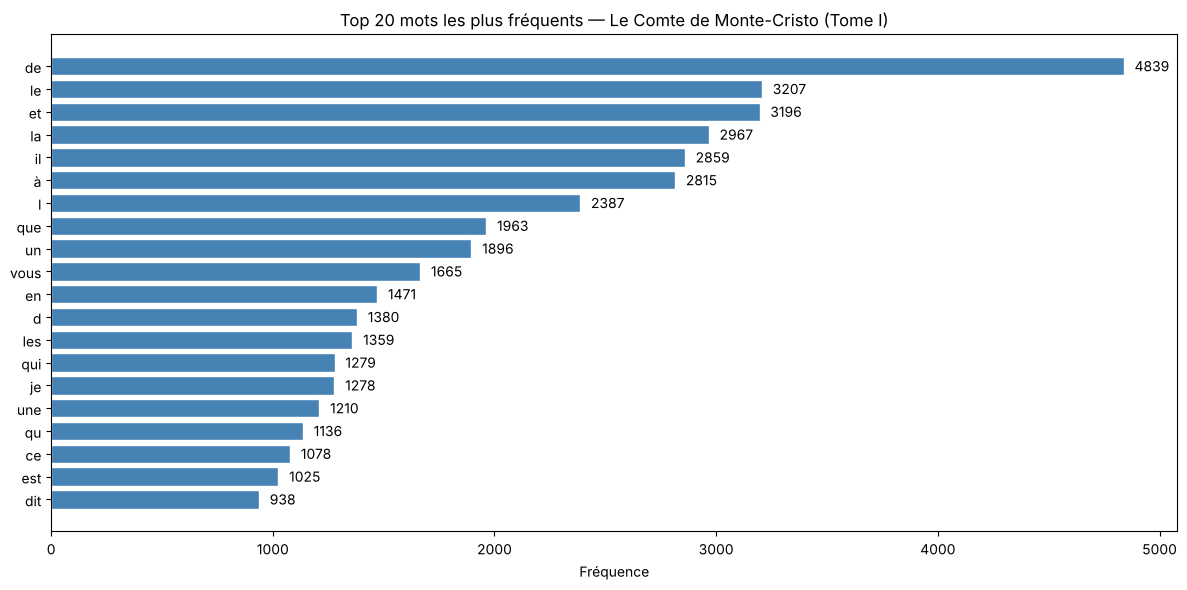

In [18]:
plot_top_frequences(top20, 'Top 20 mots les plus fréquents — Le Comte de Monte-Cristo (Tome I)',
                    name='05_top20_frequences')

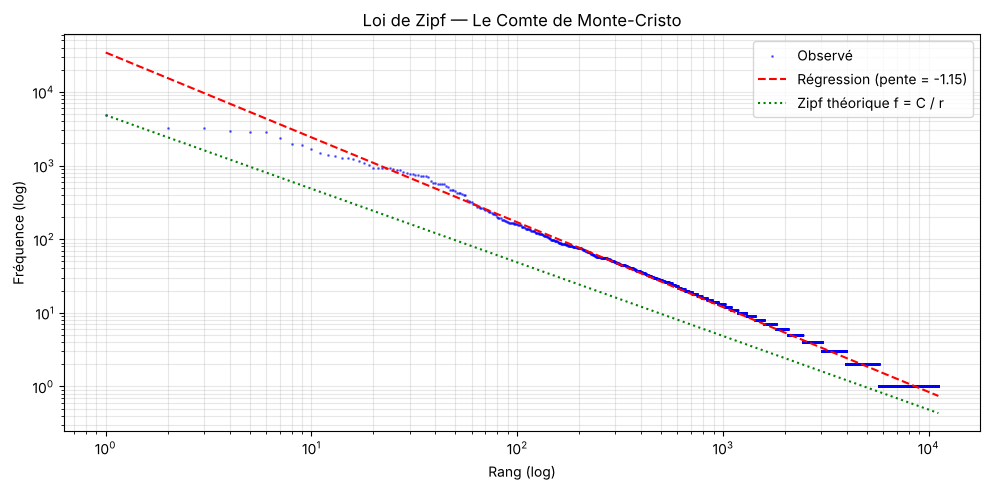

Pente log-log globale        : -1.153  (Zipf idéal : -1)
Pente sur les 1000 premiers  : -1.087
  Rang 1: de    (4839 fois) — ratio avec rang 1 : 1.00
  Rang 2: le    (3207 fois) — ratio avec rang 1 : 1.51
  Rang 3: et    (3196 fois) — ratio avec rang 1 : 1.51
  Rang 4: la    (2967 fois) — ratio avec rang 1 : 1.63
  Rang 5: il    (2859 fois) — ratio avec rang 1 : 1.69


In [19]:
# c) Loi de Zipf
fit = zipf_fit(freq)
fit_1000 = zipf_fit(freq, max_rank=1000)
plot_zipf(fit, 'Loi de Zipf — Le Comte de Monte-Cristo', name='05_loi_de_zipf')
print(f"Pente log-log globale        : {fit['pente']:.3f}  (Zipf idéal : -1)")
print(f"Pente sur les 1000 premiers  : {fit_1000['pente']:.3f}")
top5 = freq.most_common(5)
for i, (m, n) in enumerate(top5):
    print(f'  Rang {i+1}: {m:<5} ({n} fois) — ratio avec rang 1 : {top5[0][1]/n:.2f}')

In [20]:
# d) Mots thématiques / e) Hapax
classement = rangs(freq)
for m in ['dantès', 'vengeance', 'liberté', 'prison']:
    print(f"d) {m:<10} fréquence = {freq[m]:>4}   rang = {classement.get(m, '—')}")
hap = hapax(freq)
print(f'\ne) Hapax legomena : {len(hap):,} mots = {len(hap)/len(freq)*100:.1f}% du vocabulaire '
      f'mais {len(hap)/len(tokens)*100:.2f}% des tokens')
random.seed(0)
print('   Exemples :', random.sample(hap, 25))

d) dantès     fréquence =  777   rang = 30
d) vengeance  fréquence =   11   rang = 1126
d) liberté    fréquence =   49   rang = 301
d) prison     fréquence =   67   rang = 220

e) Hapax legomena : 5,434 mots = 48.8% du vocabulaire mais 4.16% des tokens
   Exemples : ['bêche', 'rapportant', 'vengent', 'raviserait', 'langoureux', 'méritaient', 'inégaux', 'remonté', 'scindaient', 'indubitablement', 'cinquante-sept', 'partisan', 'ceinturés', 'commissions', 'condamnée', 'arriverai', 'exterminateur', 'convenance', 'licite', 'planton', 'cavités', 'triples', 'montraient', 'émission', 'concilie']


---
# Partie 6 — Stop words (`src/preprocessing/stop_words_filter.py`)

In [21]:
c_sw = compare_stopword_lists(sw_nltk, sw_spacy)
print(f"a) Stop words NLTK  : {c_sw['A']}\n   Stop words SpaCy : {c_sw['B']}")
print(f"   Communs          : {c_sw['communs']}\n   Union            : {c_sw['union']}")
print(f"\nDans NLTK, absents de SpaCy ({len(c_sw['seulement_A'])}) : {c_sw['seulement_A'][:25]}")
print(f"Dans SpaCy, absents de NLTK ({len(c_sw['seulement_B'])}) : {c_sw['seulement_B'][:25]}")

a) Stop words NLTK  : 157
   Stop words SpaCy : 507
   Communs          : 85
   Union            : 579

Dans NLTK, absents de SpaCy (72) : ['aient', 'aies', 'aurai', 'aurais', 'auras', 'aurez', 'auriez', 'aurions', 'aurons', 'avez', 'aviez', 'avions', 'ayante', 'ayantes', 'ayants', 'ayez', 'ayons', 'c', 'd', 'eue', 'eues', 'eurent', 'eus', 'eusse', 'eussent']
Dans SpaCy, absents de NLTK (422) : ['a', 'abord', 'afin', 'ah', 'ainsi', 'allaient', 'allons', 'alors', 'anterieur', 'anterieure', 'anterieures', 'antérieur', 'antérieure', 'antérieures', 'apres', 'après', 'assez', 'attendu', 'aupres', 'auquel', 'aussi', 'autre', 'autrement', 'autres', 'autrui']


In [22]:
sw_custom = build_custom_stopwords(nlp)          # NLTK ∪ SpaCy ∪ stop words contextuels
tokens_no_stop = filter_tokens(tokens, sw_custom, min_len=3)
freq_clean = Counter(tokens_no_stop)
print(f'Tokens avant : {len(tokens):,}')
print(f'Tokens après : {len(tokens_no_stop):,}')
print(f'c) Réduction (tokens)     : {(len(tokens)-len(tokens_no_stop))/len(tokens)*100:.1f}%')
print(f'   Réduction (vocabulaire): {(1-len(set(tokens_no_stop))/len(set(tokens)))*100:.1f}% '
      f'({len(set(tokens)):,} -> {len(set(tokens_no_stop)):,} types)')
print('\nb) Top 20 après suppression des stop words :')
for mot, n in freq_clean.most_common(20):
    print(f'   {mot:<20} {n}')

print(f'\n{"Rang":<5} {"Avant":<22} {"Après"}'); print('-' * 45)
for i, (a, b) in enumerate(zip([m for m, _ in freq.most_common(10)], [m for m, _ in freq_clean.most_common(10)]), 1):
    print(f'{i:<5} {a:<22} {b}')

Tokens avant : 130,542
Tokens après : 50,389
c) Réduction (tokens)     : 61.4%
   Réduction (vocabulaire): 4.3% (11,142 -> 10,668 types)

b) Top 20 après suppression des stop words :
   dantès               777
   homme                424
   morrel               273
   villefort            258
   edmond               247
   faire                225
   caderousse           219
   jeune                217
   abbé                 214
   père                 193
   fois                 167
   danglars             166
   rien                 165
   fernand              161
   temps                157
   demanda              155
   yeux                 154
   fit                  141
   point                139
   jour                 138

Rang  Avant                  Après
---------------------------------------------
1     de                     dantès
2     le                     homme
3     et                     morrel
4     la                     villefort
5     il                     

In [23]:
# d) Justification des stop words contextuels
for m in ['dit', 'répondit', 'reprit', 'monsieur', 'madame']:
    print(f'{m:<10} {freq[m]:>5} occurrences (rang {classement.get(m)})')
print('\nMots qui suivent "monsieur" :', Counter(b for a, b in bigrams(tokens) if a == 'monsieur').most_common(8))
print('Mots qui suivent "dit/répondit" :',
      Counter(b for a, b in bigrams(tokens) if a in ('dit', 'répondit')).most_common(8))

dit          938 occurrences (rang 20)
répondit     137 occurrences (rang 114)
reprit       119 occurrences (rang 128)
monsieur     333 occurrences (rang 58)
madame        17 occurrences (rang 770)

Mots qui suivent "monsieur" : [('dit', 56), ('morrel', 35), ('le', 19), ('de', 17), ('répondit', 14), ('et', 13), ('je', 13), ('l', 13)]
Mots qui suivent "dit/répondit" : [('il', 151), ('le', 132), ('l', 127), ('caderousse', 78), ('dantès', 77), ('danglars', 45), ('villefort', 38), ('la', 33)]


personnage  fréquence  rang (après stop words)
    dantès        777                        1
    morrel        273                        3
 villefort        258                        4
    edmond        247                        5
caderousse        219                        7
      abbé        214                        9
  danglars        166                       12
   fernand        161                       14
  mercédès        138                       21
     faria        105                       32
     franz         73                       69
  noirtier         40                      179
    albert          4                     2634


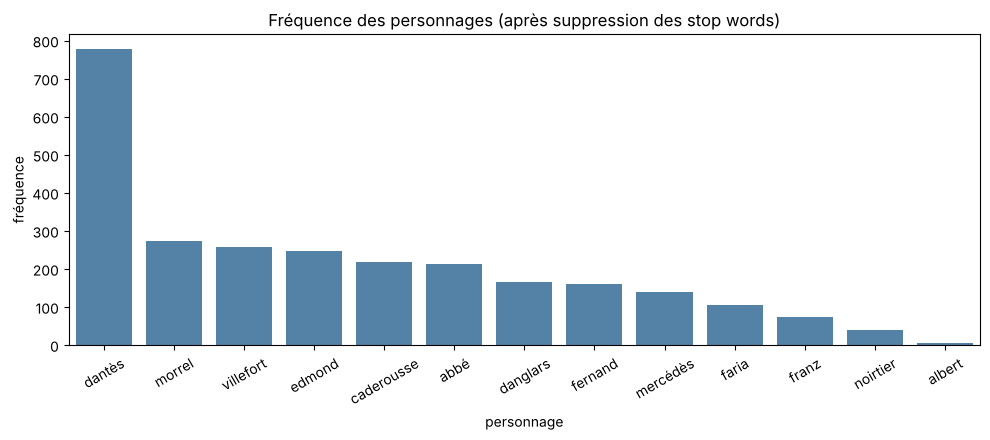

In [24]:
# e) Personnages
persos = ['dantès', 'edmond', 'danglars', 'fernand', 'villefort', 'faria', 'abbé', 'mercédès',
          'morrel', 'caderousse', 'franz', 'albert', 'noirtier']
rang_clean = rangs(freq_clean)
df_persos = pd.DataFrame({'personnage': persos, 'fréquence': [freq_clean[p] for p in persos],
                          'rang (après stop words)': [rang_clean.get(p) for p in persos]}
                         ).sort_values('fréquence', ascending=False)
print(df_persos.to_string(index=False))
plt.figure(figsize=(10, 4.5))
sns.barplot(data=df_persos, x='personnage', y='fréquence', color='steelblue')
plt.title('Fréquence des personnages (après suppression des stop words)')
plt.xticks(rotation=30); plt.tight_layout(); save_fig('06_personnages')

---
# Partie 7 — WordCloud (`src/analytics/visualization.py`, `src/analytics/characters.py`)

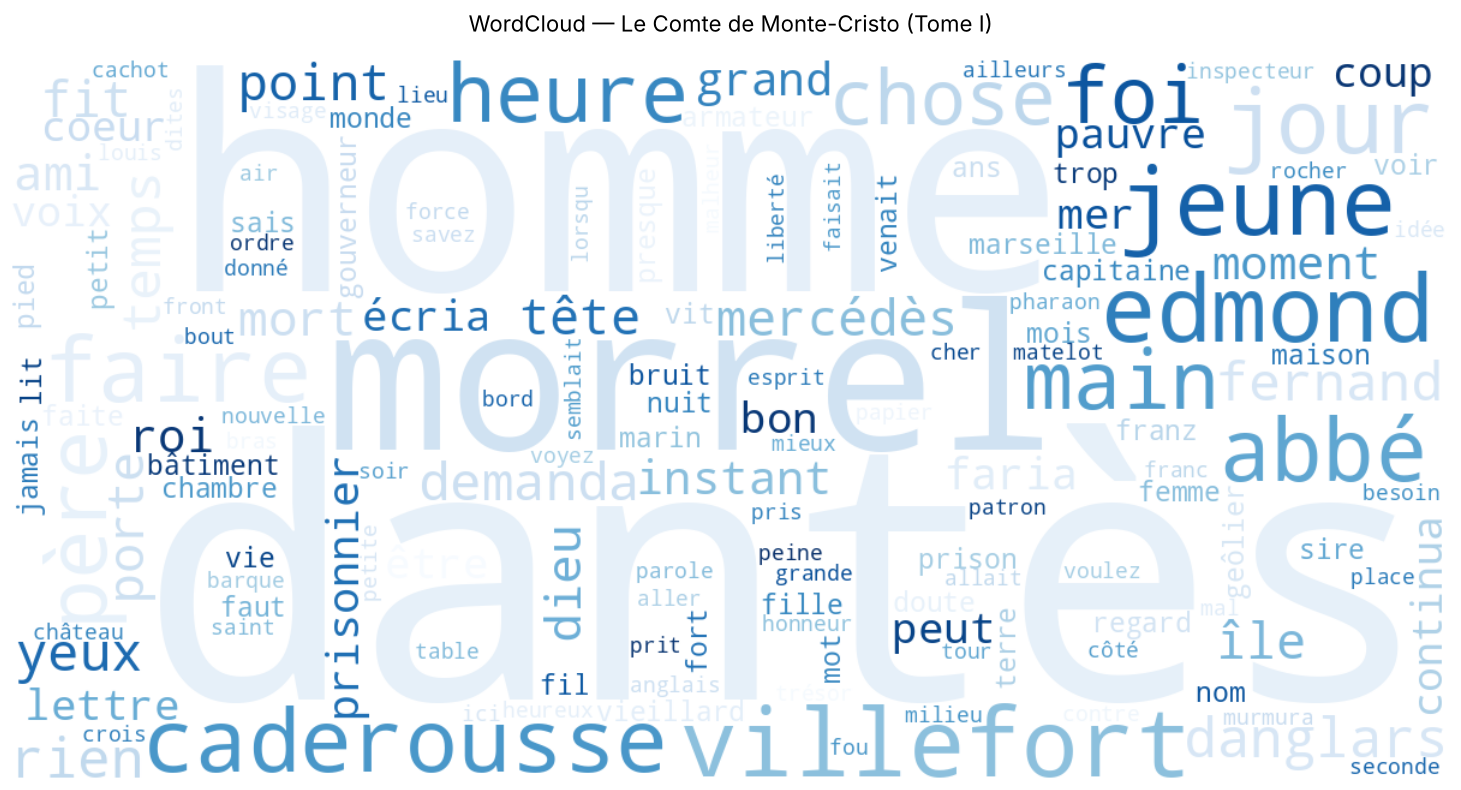

a) 5 mots les plus visibles : ['dantès', 'homme', 'morrel', 'villefort', 'jeune']


In [25]:
texte_clean = ' '.join(tokens_no_stop)
wc = make_wordcloud(texte_clean, max_words=150, min_font_size=8)
show_wordcloud(wc, 'WordCloud — Le Comte de Monte-Cristo (Tome I)', name='07_wordcloud_roman')
print('a) 5 mots les plus visibles :', list(wc.words_.keys())[:5])

### b) Par personnage
Le code du sujet appelle `sent_tokenize(roman_clean)` → **une seule phrase** (tout le roman) : les nuages seraient
identiques. On segmente le texte **brut** en phrases, puis on nettoie chaque phrase ; le nom du personnage est
retiré de son nuage et on calcule ses **mots distinctifs**.

Dantès      743 phrases | top fréquents : ['homme', 'faire', 'abbé', 'edmond', 'villefort', 'yeux', 'point', 'temps']
           mots distinctifs : ['fragments', 'puissance', 'releva', 'tombant', 'dalles', 'assiette', 'rendait', 'crique', 'reconnut', 'pioche']


Danglars    162 phrases | top fréquents : ['caderousse', 'fernand', 'dantès', 'morrel', 'homme', 'capitaine', 'jeune', 'armateur']
           mots distinctifs : ['écriture', 'dénonciation', 'comprends', 'vois', 'fernand', 'gauche', 'caderousse', 'belle', 'garçon', 'capitaine']


Villefort   252 phrases | top fréquents : ['dantès', 'homme', 'père', 'jeune', 'main', 'renée', 'lettre', 'morrel']
           mots distinctifs : ['certificat', 'prévenus', 'croix', 'pétition', 'saint-méran', 'mlle', 'valet', 'services', 'officier', 'juge']


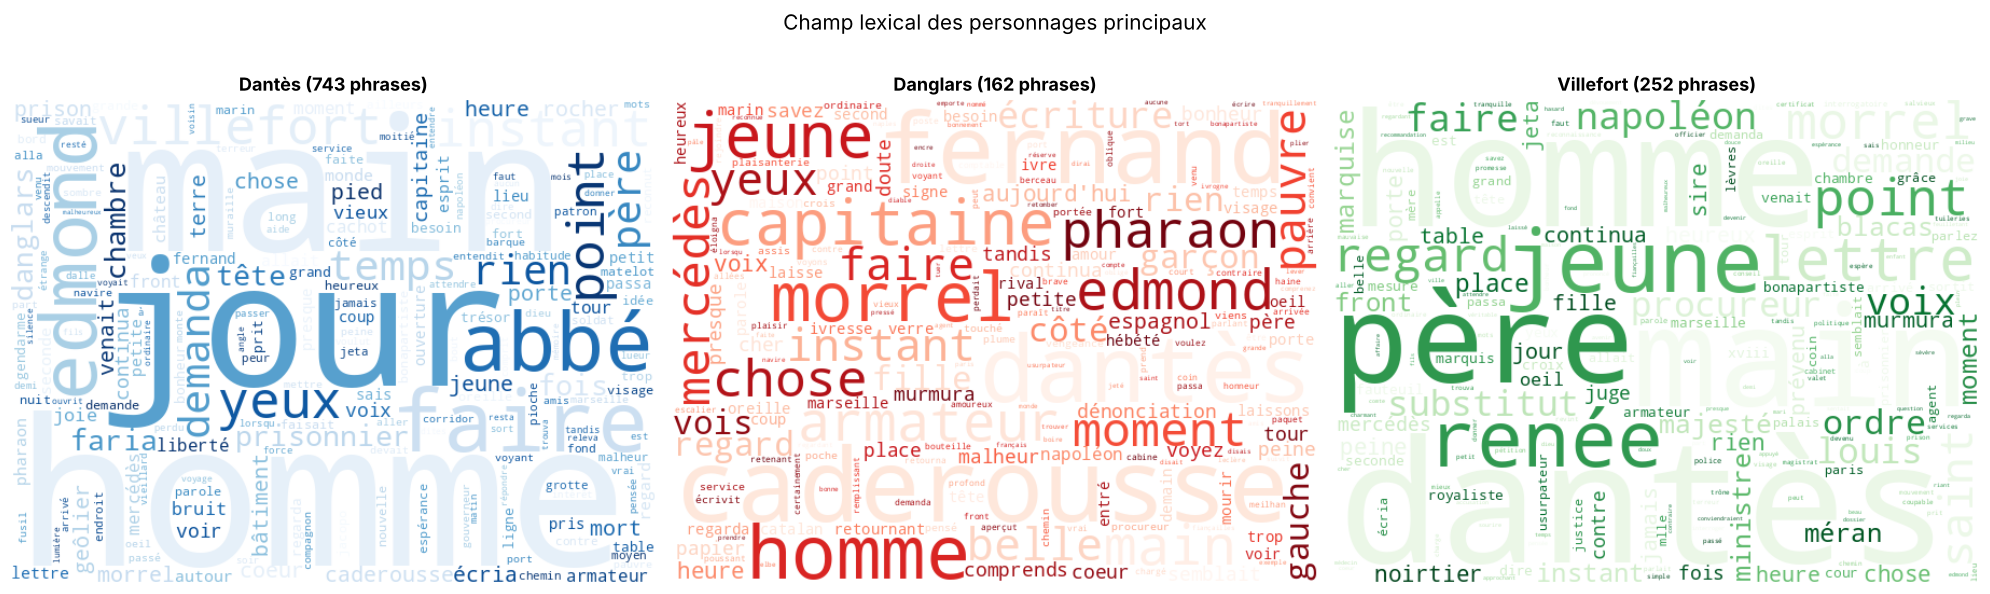

In [26]:
phrases_clean_list = [clean_text_v2(p) for p in phrases_roman]
clouds, titres = [], []
for perso, cmap in zip(['dantès', 'danglars', 'villefort'], ['Blues', 'Reds', 'Greens']):
    sel, toks = tokens_personnage(phrases_clean_list, perso, sw_custom, min_len=4)
    clouds.append(make_wordcloud(' '.join(toks), width=600, height=450, colormap=cmap))
    titres.append(f'{perso.capitalize()} ({len(sel)} phrases)')
    print(f'{perso.capitalize():<10} {len(sel):>4} phrases | top fréquents : {[m for m, _ in Counter(toks).most_common(8)]}')
    print(f'{"":<10} mots distinctifs : {mots_distinctifs(toks, freq_clean)}')
wordcloud_grid(clouds, titres, 'Champ lexical des personnages principaux', name='07_wordcloud_personnages')

### c) Noms propres (PROPN) — sur le texte brut, car la détection a besoin des majuscules

SpaCy sur tout le roman : 5.3 s (4,201 paragraphes)
Top 30 PROPN : [('Dantès', 287), ('Morrel', 272), ('Villefort', 256), ('Edmond', 247), ('Caderousse', 175), ('Danglars', 161), ('Fernand', 155), ('Mercédès', 126), ('Dieu', 123), ('Marseille', 75), ('Franz', 70), ('Pharaon', 63), ('Louis', 53), ('mer', 44), ('Paris', 44), ('Majesté', 42), ('Monte', 41), ('Jacopo', 41), ('Cristo', 40), ('France', 37), ('Elbe', 36), ('Napoléon', 36), ('rocher', 35), ('Faria', 33), ('Gaetano', 32), ('Anglais', 28), ('Emmanuel', 27), ('Julie', 27), ('Blacas', 26), ('calme', 23)]


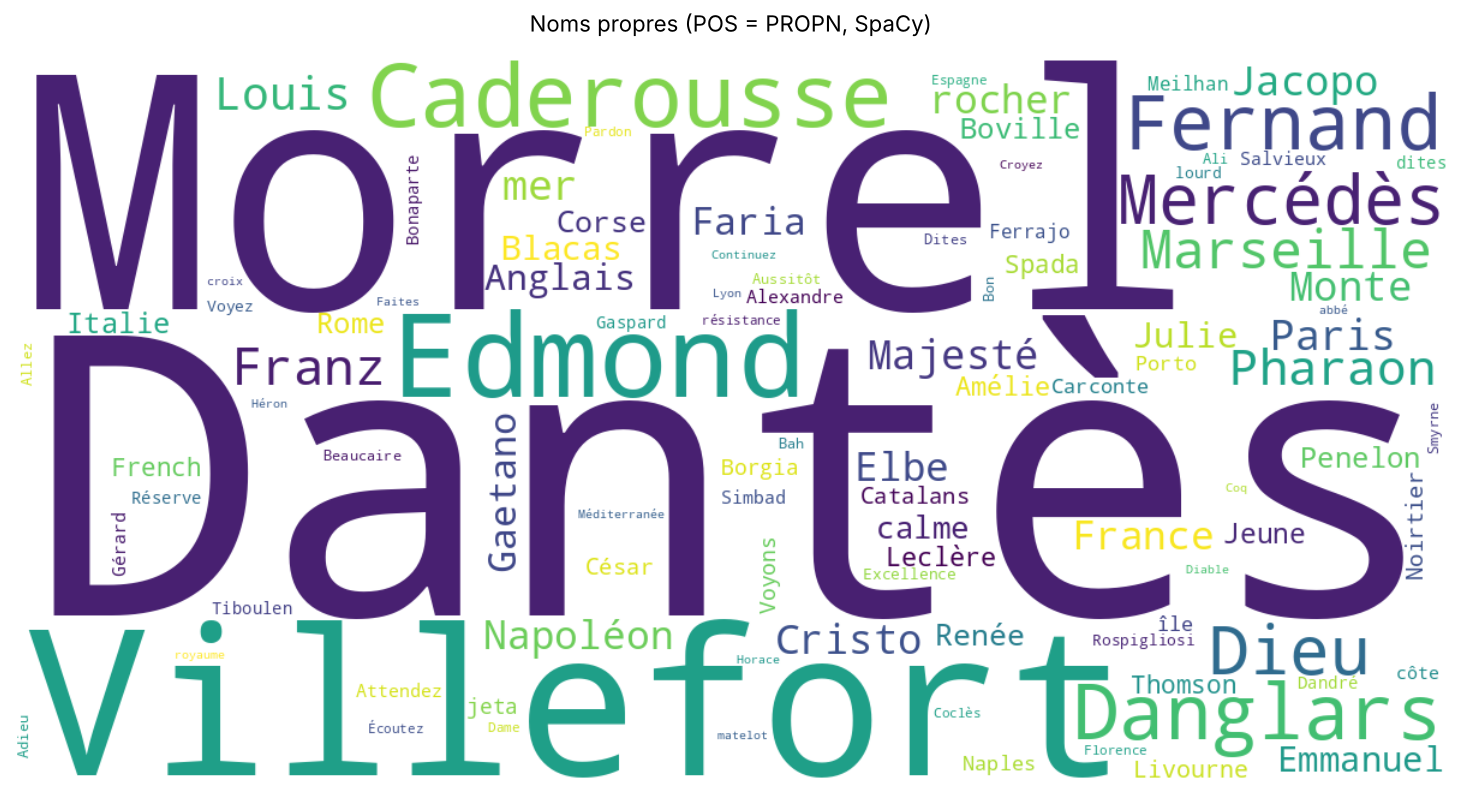

In [27]:
t0 = time.time()
paragraphes = [prep_brut(p) for p in re.split(r'\n\s*\n', roman) if p.strip()]
freq_propn = extraire_propn(nlp, paragraphes, exclude=sw_custom)
print(f'SpaCy sur tout le roman : {time.time()-t0:.1f} s ({len(paragraphes):,} paragraphes)')
print('Top 30 PROPN :', freq_propn.most_common(30))
show_wordcloud(make_wordcloud(frequencies=freq_propn, colormap='viridis', max_words=100),
               'Noms propres (POS = PROPN, SpaCy)', name='07_wordcloud_noms_propres')

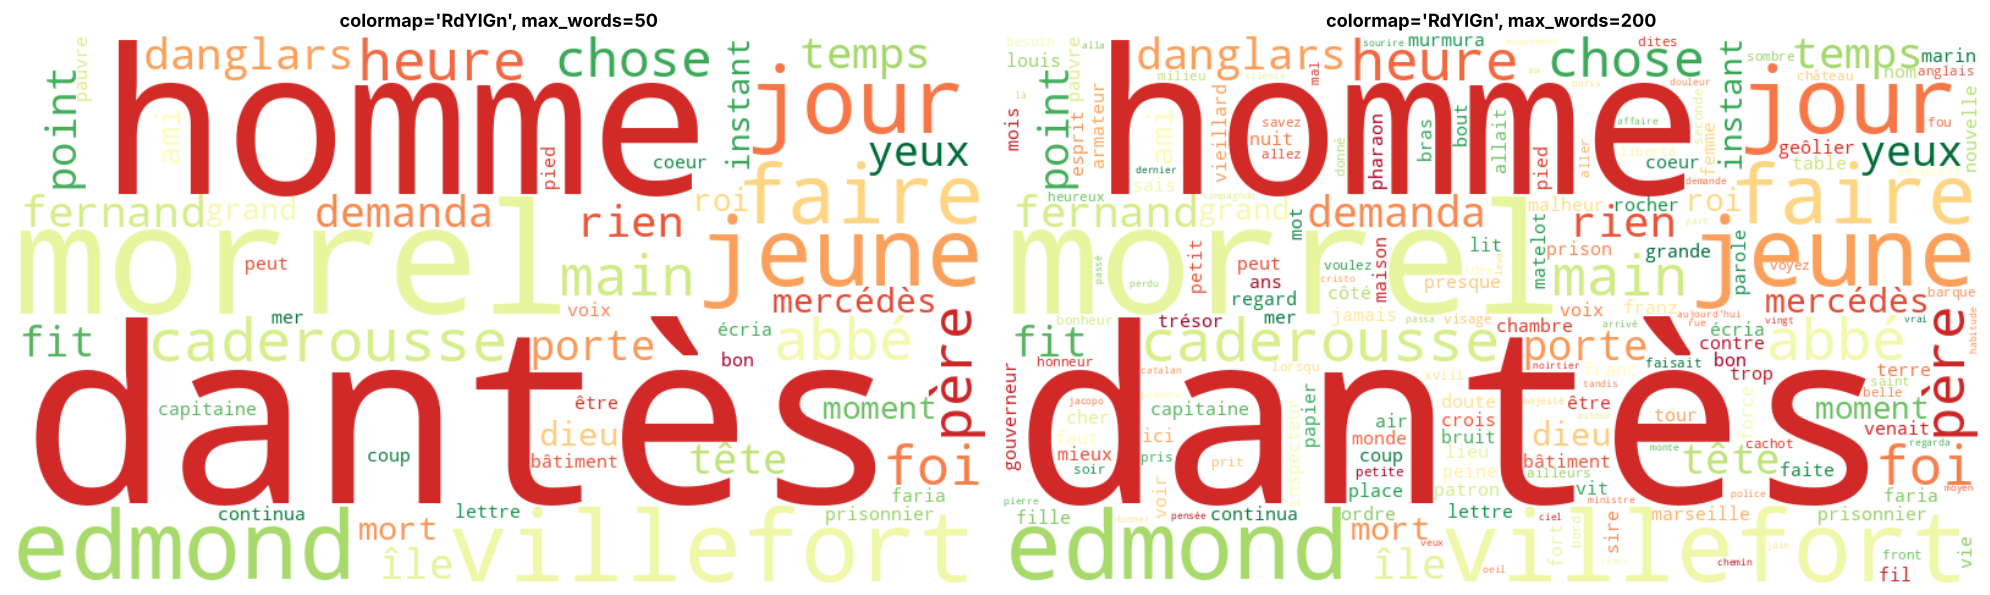

In [28]:
# d) Paramètres
wordcloud_grid([make_wordcloud(texte_clean, width=800, height=450, colormap='RdYlGn', max_words=mw)
                for mw in (50, 200)],
               ["colormap='RdYlGn', max_words=50", "colormap='RdYlGn', max_words=200"],
               name='07_wordcloud_parametres')

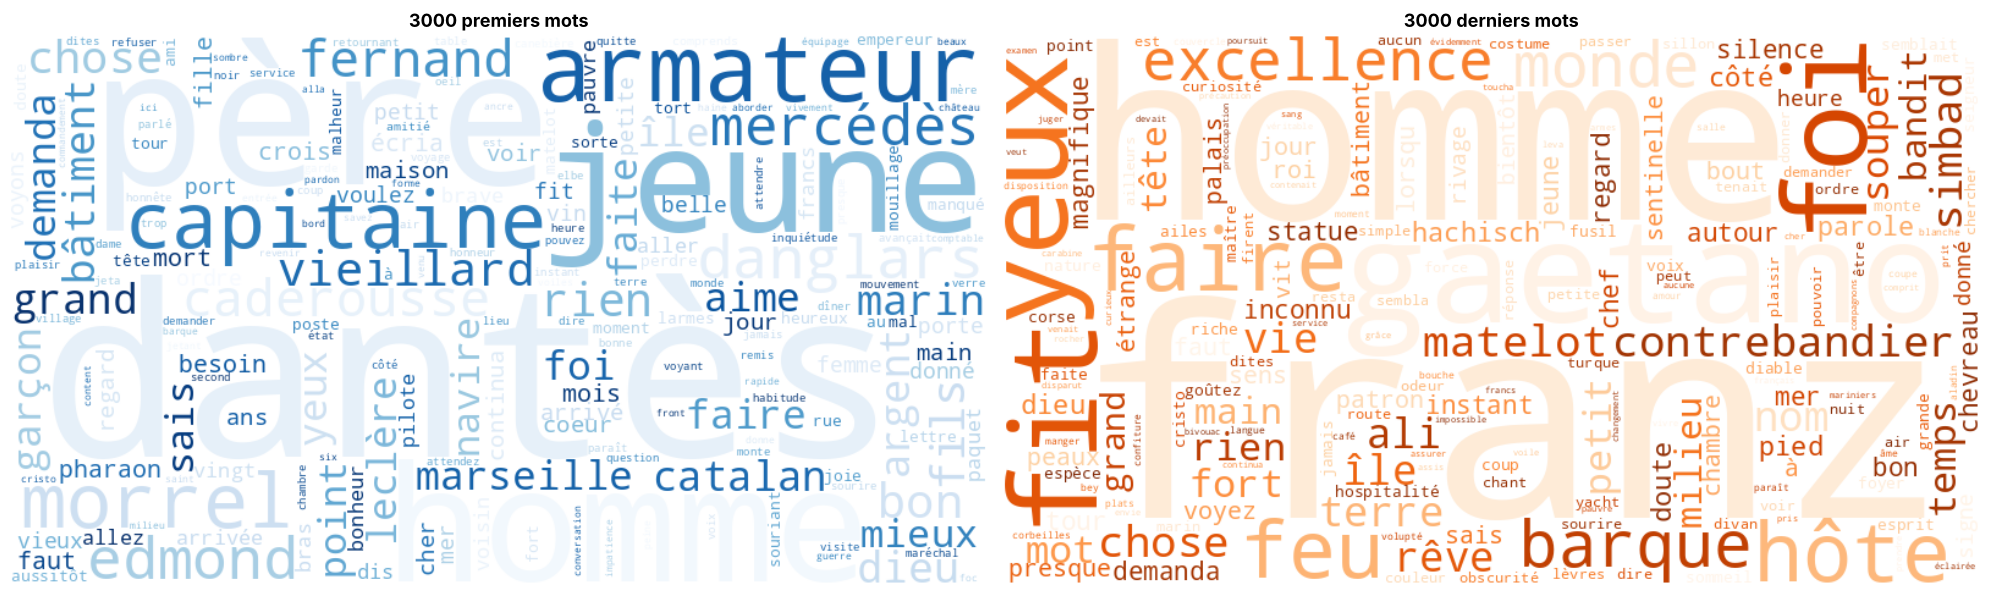

Top début : ['dantès', 'père', 'jeune', 'homme', 'capitaine', 'morrel', 'armateur', 'danglars', 'edmond', 'mercédès', 'caderousse', 'fernand', 'vieillard', 'fils', 'bon']
Top fin   : ['franz', 'gaetano', 'homme', 'fit', 'yeux', 'faire', 'fois', 'feu', 'barque', 'monde', 'hôte', 'excellence', 'simbad', 'vie', 'nom']
Vocabulaire commun : 442 mots sur 1508 (début) / 1738 (fin) — Jaccard = 0.16


In [29]:
# e) Début vs fin
debut, fin = tokens_no_stop[:3000], tokens_no_stop[-3000:]
wordcloud_grid([make_wordcloud(' '.join(debut), width=800, height=450, colormap='Blues'),
                make_wordcloud(' '.join(fin), width=800, height=450, colormap='Oranges')],
               ['3000 premiers mots', '3000 derniers mots'], name='07_wordcloud_debut_fin')
print('Top début :', [m for m, _ in Counter(debut).most_common(15)])
print('Top fin   :', [m for m, _ in Counter(fin).most_common(15)])
communs = set(debut) & set(fin)
print(f'Vocabulaire commun : {len(communs)} mots sur {len(set(debut))} (début) / {len(set(fin))} (fin) '
      f'— Jaccard = {len(communs)/len(set(debut)|set(fin)):.2f}')

---
# Partie 8 — Stemming (`src/preprocessing/stemmer.py`)

In [30]:
stemmer = get_stemmer('french')
familles = {'vengeance': ['vengeance', 'venger', 'vengeur', 'vindicatif'],
            'prison': ['prison', 'prisonnier', 'emprisonner', 'emprisonnement'],
            'liberté': ['liberté', 'libérer', 'libérateur', 'libération'],
            'mer': ['mer', 'marin', 'maritime', 'navire', 'naviguer']}
print(f'{"Famille":<11}{"Mot original":<20} {"Racine (stem)"}'); print('-' * 50)
print(f'{"":<11}{"dantès":<20} {stemmer.stem("dantès")}')
for fam, ms in familles.items():
    for m in ms:
        print(f'{fam:<11}{m:<20} {stemmer.stem(m)}')
    rac = sorted({stemmer.stem(m) for m in ms})
    print(f'{"":<11}-> {len(rac)} racine(s) distincte(s) : {rac}')

Famille    Mot original         Racine (stem)
--------------------------------------------------
           dantès               dantes
vengeance  vengeance            vengeanc
vengeance  venger               veng
vengeance  vengeur              vengeur
vengeance  vindicatif           vindiqu
           -> 4 racine(s) distincte(s) : ['veng', 'vengeanc', 'vengeur', 'vindiqu']
prison     prison               prison
prison     prisonnier           prisonni
prison     emprisonner          emprison
prison     emprisonnement       emprison
           -> 3 racine(s) distincte(s) : ['emprison', 'prison', 'prisonni']
liberté    liberté              libert
liberté    libérer              liber
liberté    libérateur           liber
liberté    libération           liber
           -> 2 racine(s) distincte(s) : ['liber', 'libert']
mer        mer                  mer
mer        marin                marin
mer        maritime             maritim
mer        navire               navir
mer        navigue

In [31]:
# b) Corpus
tokens_stemmed = stem_tokens(tokens_no_stop, stemmer)
freq_stemmed = Counter(tokens_stemmed)
v_av, v_ap = len(set(tokens_no_stop)), len(set(tokens_stemmed))
print(f'Vocabulaire avant stemming : {v_av:,} mots')
print(f'Vocabulaire après stemming : {v_ap:,} racines')
print(f'b) Réduction du vocabulaire : {(1 - v_ap/v_av)*100:.1f}%')
print('\nTop 20 racines :')
for r, n in freq_stemmed.most_common(20):
    print(f'   {r:<20} {n}')

groupes = familles_par_racine(tokens_no_stop, stemmer)
print('\nFamilles de mots (10 plus grandes) :')
for racine, ms in sorted(groupes.items(), key=lambda x: len(x[1]), reverse=True)[:10]:
    print(f'  [{racine:<12}] ({len(ms):>2}) -> {sorted(ms)[:8]}')

Vocabulaire avant stemming : 10,668 mots
Vocabulaire après stemming : 5,581 racines
b) Réduction du vocabulaire : 47.7%

Top 20 racines :
   dantes               777
   homm                 509
   morrel               273
   demand               266
   villefort            258
   edmond               247
   port                 234
   jeun                 228
   fair                 225
   caderouss            219
   jour                 215
   abbé                 214
   regard               209
   don                  202
   per                  201
   main                 195
   pass                 191
   heur                 178
   grand                170
   fois                 167

Familles de mots (10 plus grandes) :
  [port        ] (20) -> ['port', 'porta', 'portaient', 'portais', 'portait', 'portant', 'porte', 'porter']
  [trouv       ] (20) -> ['trouva', 'trouvai', 'trouvaient', 'trouvait', 'trouvant', 'trouve', 'trouver', 'trouvera']
  [don         ] (19) -> ['don', 'donn

In [32]:
# c) Faux amis du stemmer
for groupe in [('porte', 'porter', 'port'), ('sort', 'sortir', 'sortie'), ('mari', 'marin', 'marine'),
               ('vers', 'verser', 'verre'), ('livre', 'livrer', 'libre'), ('somme', 'sommeil', 'sommes'),
               ('pas', 'passer', 'passion'), ('mère', 'mer', 'merci'), ('été', 'étaient', 'état')]:
    print('  ', ' | '.join(f'{m} -> {stemmer.stem(m)}' for m in groupe))

   porte -> port | porter -> port | port -> port
   sort -> sort | sortir -> sort | sortie -> sort
   mari -> mar | marin -> marin | marine -> marin
   vers -> ver | verser -> vers | verre -> verr
   livre -> livr | livrer -> livr | libre -> libr
   somme -> somm | sommeil -> sommeil | sommes -> somm
   pas -> pas | passer -> pass | passion -> passion
   mère -> mer | mer -> mer | merci -> merc
   été -> été | étaient -> étaient | état -> état


In [33]:
# d) 15 mots caractéristiques / e) racines thématiques
mots_15 = ['vengeance', 'prisonnier', 'château', 'liberté', 'navire', 'trésor', 'abbé', 'capitaine',
           'mariage', 'procureur', 'emprisonné', 'évasion', 'fiançailles', 'cachot', 'marseille']
print(stem_table(mots_15, set(tokens), freq, stemmer).to_string(index=False))
print("\n(« Intelligible » = le radical est lui-même un mot attesté dans le roman)\n")
print(racines_thematiques(freq_stemmed, groupes,
                          {'veng-': 'veng', 'pris-': 'pris', 'liber-': 'liber', 'dant-': 'dant'}).to_string(index=False))

Mot original Radical (Snowball) Intelligible ?  Fréq. du mot
   vengeance           vengeanc            non            11
  prisonnier           prisonni            non            80
     château            château            oui            50
     liberté             libert            non            49
      navire              navir            non            32
      trésor             trésor            oui            45
        abbé               abbé            oui           214
   capitaine           capitain            non            87
     mariage             mariag            non             8
   procureur          procureur            oui            32
  emprisonné           emprison            non             1
     évasion               évas            non             9
 fiançailles          fiançaill            non            18
      cachot             cachot            oui            46
   marseille            marseil            non            84

(« Intelligible » = le 

---
# Partie 9 — Lemmatisation (`src/preprocessing/lemmatizer.py`)

In [34]:
chap1 = prep_brut(chapitres['I']['texte'])
t0 = time.time()
doc, df_tokens = analyse_spacy(nlp, chap1)
t_ch1 = time.time() - t0
df_tokens.to_csv(OUT_DIR / 'chapitre1_spacy_tokens.csv', index=False)
print(f'Chapitre I : « {chapitres["I"]["titre"]} » — {len(df_tokens):,} tokens analysés en {t_ch1:.2f} s')
print('(DataFrame complet exporté dans outputs/chapitre1_spacy_tokens.csv)\n')
print(df_tokens.head(40).to_string(index=False))

Chapitre I : « Marseille.--L'arrivée. » — 4,189 tokens analysés en 0.48 s
(DataFrame complet exporté dans outputs/chapitre1_spacy_tokens.csv)

     token      lemme   POS  est_stop  est_ponc
 Marseille  Marseille PROPN     False     False
         .          . PUNCT     False      True
         —          — PUNCT     False      True
        L'         le   DET      True     False
   arrivée    arrivée  NOUN     False     False
         .          . PUNCT     False      True
        Le         le   DET      True     False
        24         24   NUM     False     False
   février    février  NOUN     False     False
      1815       1815   NUM     False     False
         ,          , PUNCT     False      True
        la         le   DET      True     False
     vigie      vigie  NOUN     False     False
        de         de   ADP      True     False
Notre-Dame Notre-Dame PROPN     False     False
        de         de   ADP      True     False
        la         le   DET      True    

In [35]:
print('Top 20 lemmes (chapitre I) :')
for l, n in Counter(lemmes_propres(doc)).most_common(20):
    print(f'   {l:<20} {n}')
print('\nb) Top 15 NOMS (lemmatisés) :', lemmes_par_pos(doc, 'NOUN').most_common(15))
print('\nc) Noms propres :', lemmes_par_pos(doc, 'PROPN', exclude=sw_custom, lemma=False,
                                           skip_stop=False).most_common(25))
print('\n   (complément NER) :', Counter((e.text, e.label_) for e in doc.ents).most_common(15))

Top 20 lemmes (chapitre I) :
   monsieur             32
   armateur             28
   être                 23
   avoir                23
   morrel               22
   jeune                20
   dantès               20
   homme                19
   il                   17
   danglars             17
   dantè                17
   capitaine            16
   bien                 15
   demander             14
   oui                  12
   bâtiment             11
   marin                11
   navire               10
   grand                10
   leclère              10

b) Top 15 NOMS (lemmatisés) : [('monsieur', 32), ('armateur', 28), ('homme', 19), ('capitaine', 16), ('dantè', 14), ('bâtiment', 11), ('île', 9), ('père', 9), ('navire', 8), ('oeil', 7), ('ordre', 7), ('pilote', 6), ('port', 6), ('fils', 6), ('paquet', 6)]

c) Noms propres : [('Morrel', 21), ('Danglars', 17), ('Dantès', 15), ('Leclère', 10), ('Edmond', 10), ('Pharaon', 8), ('Marseille', 4), ('Elbe', 4), ('jeta', 3), ('Porto', 

  POS           catégorie   n    %
PUNCT         Ponctuation 719 17.2
 NOUN          Nom commun 662 15.8
 PRON              Pronom 508 12.1
  ADP         Préposition 463 11.1
 VERB               Verbe 453 10.8
  DET         Déterminant 421 10.1
  ADV             Adverbe 240  5.7
  ADJ            Adjectif 190  4.5
PROPN          Nom propre 169  4.0
  AUX          Auxiliaire 128  3.1
CCONJ  Conj. coordination 117  2.8
SCONJ Conj. subordination  92  2.2
  NUM             Numéral  26  0.6
    X               Autre   1  0.0


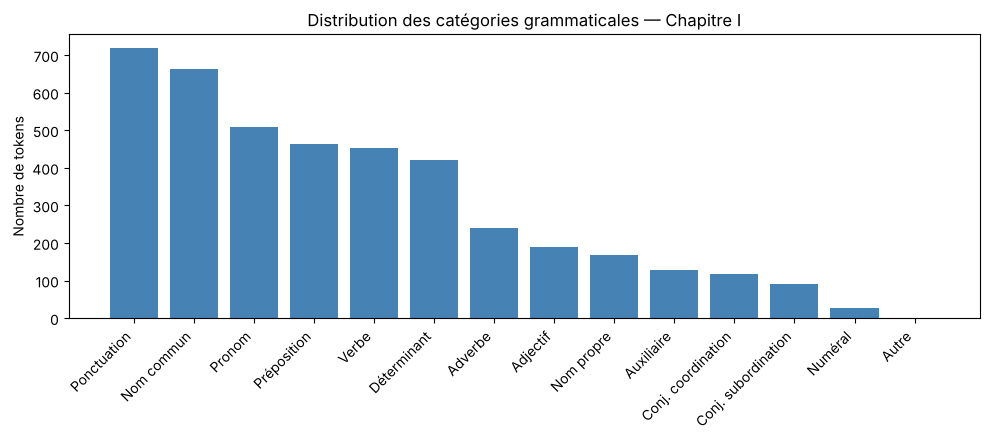

In [36]:
# 9.3 POS
df_pos = pos_distribution(doc)
print(df_pos.to_string(index=False))
plt.figure(figsize=(10, 4.5))
plt.bar(df_pos['catégorie'], df_pos['n'], color='steelblue'); plt.ylabel('Nombre de tokens')
plt.title('Distribution des catégories grammaticales — Chapitre I'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); save_fig('09_pos_chapitre1')

In [37]:
# d) Stemming vs lemmatisation (lemme calculé dans une phrase réelle du roman)
cibles = ['navire', 'prisonnier', 'vengeance', 'chevaux', 'yeux', 'allait', 'fut', 'meilleurs',
          'aperçut', 'gendarmes', 'prisonniers', 'disait', 'émotion', 'jeunes', 'dantès']
attendu = {'navire': 'navire', 'prisonnier': 'prisonnier', 'vengeance': 'vengeance', 'chevaux': 'cheval',
           'yeux': 'œil', 'allait': 'aller', 'fut': 'être', 'meilleurs': 'bon (ou meilleur)',
           'aperçut': 'apercevoir', 'gendarmes': 'gendarme', 'prisonniers': 'prisonnier', 'disait': 'dire',
           'émotion': 'émotion', 'jeunes': 'jeune', 'dantès': 'dantès'}
df_cmp = stem_vs_lemma(nlp, stemmer, cibles, phrases_roman, attendu)
print(df_cmp.to_string(index=False))
print(f"\nStemming correct : {(df_cmp['Stem correct ?']=='oui').sum()}/15 | "
      f"Lemmatisation correcte : {(df_cmp['Lemme correct ?']=='oui').sum()}/15")
df_cmp.to_csv(OUT_DIR / 'stemming_vs_lemmatisation.csv', index=False)

Mot original Stemming (Snowball) Lemme (SpaCy)   POS           Attendu Stem correct ? Lemme correct ?
      navire               navir        navire  VERB            navire            non             oui
  prisonnier            prisonni    prisonnier  NOUN        prisonnier            non             oui
   vengeance            vengeanc     vengeance  NOUN         vengeance            non             oui
     chevaux              cheval        cheval  NOUN            cheval            oui             oui
        yeux                yeux          yeux   ADJ               œil            non             non
      allait              allait         aller  VERB             aller            non             oui
         fut                 fut          être   AUX              être            non             oui
   meilleurs            meilleur      meilleur  NOUN bon (ou meilleur)            non             non
     aperçut             aperçut    apercevoir  VERB        apercevoir            

In [38]:
# Coût computationnel (même texte : chapitre I)
t0 = time.time(); _ = stem_tokens(tokenize_words(chap1), stemmer); tn = time.time() - t0
t0 = time.time(); _ = nlp(chap1); ts = time.time() - t0
print(f'Chapitre I ({len(chap1.split()):,} mots) : NLTK tokenisation+stemming = {tn*1000:.0f} ms | '
      f'SpaCy pipeline complet = {ts*1000:.0f} ms  -> ×{ts/tn:.0f}')

Chapitre I (3,238 mots) : NLTK tokenisation+stemming = 48 ms | SpaCy pipeline complet = 294 ms  -> ×6


---
# Partie 10 — Matrice Document-Terme & BoW (`src/vectorization/`)

In [39]:
TAILLE = 2000
blocs, noms_blocs = decouper_blocs(roman_clean, TAILLE, max_blocs=20)
mots_roman = roman_clean.split()
idx_chap = index_chapitres(chapitres, clean_text_v2)
chap_blocs = chapitres_par_bloc(len(blocs), TAILLE, idx_chap)
print(f'Nombre de blocs : {len(blocs)} (couvrent {len(blocs)*TAILLE:,} mots sur {len(mots_roman):,}, '
      f'soit {len(blocs)*TAILLE/len(mots_roman)*100:.0f}% du roman)')
print(f'Taille du premier bloc : {len(blocs[0].split())} mots')
print('Chapitres couverts :', dict(zip(noms_blocs, chap_blocs)))

Nombre de blocs : 20 (couvrent 40,000 mots sur 130,542, soit 31% du roman)
Taille du premier bloc : 2000 mots
Chapitres couverts : {'Bloc_01': 'I–I', 'Bloc_02': 'I–II', 'Bloc_03': 'II–II', 'Bloc_04': 'II–III', 'Bloc_05': 'III–III', 'Bloc_06': 'III–IV', 'Bloc_07': 'IV–V', 'Bloc_08': 'V–V', 'Bloc_09': 'V–VI', 'Bloc_10': 'VI–VI', 'Bloc_11': 'VI–VII', 'Bloc_12': 'VII–VII', 'Bloc_13': 'VII–VII', 'Bloc_14': 'VII–VIII', 'Bloc_15': 'VIII–VIII', 'Bloc_16': 'VIII–IX', 'Bloc_17': 'IX–X', 'Bloc_18': 'X–X', 'Bloc_19': 'X–XI', 'Bloc_20': 'XI–XII'}


In [40]:
vectorizer, X_bow, bow_df = build_bow(blocs, noms_blocs, stop_words=sw_custom)
print(f'a) Matrice BoW : {X_bow.shape[0]} documents × {X_bow.shape[1]} mots')
print(bow_df.iloc[:5, :8])
n_dantes = sum('dantès' in b.split() for b in blocs)
print(f"\n'dantès' dans le vocabulaire ? {'dantès' in bow_df.columns} (présent dans {n_dantes}/{len(blocs)} blocs "
      f"= {n_dantes/len(blocs):.0%} < max_df 90 % -> conservé)")
trop_frequents = sorted(w for w in set(' '.join(blocs).split())
                        if w not in sw_custom and len(w) > 2 and sum(w in b.split() for b in blocs)/len(blocs) > 0.9)
print('Mots (hors stop words) supprimés par max_df, présents dans > 90 % des blocs :', trop_frequents)

a) Matrice BoW : 20 documents × 300 mots
         affaire  agent  ailleurs  aime  air  allait  aller  allez
Bloc_01        1      1         0     0    3       0      1      0
Bloc_02        0      0         0     1    0       0      2      5
Bloc_03        0      0         0     3    0       0      2      1
Bloc_04        0      0         1     6    1       0      1      0
Bloc_05        0      0         0     1    2       1      0      0

'dantès' dans le vocabulaire ? True (présent dans 17/20 blocs = 85% < max_df 90 % -> conservé)


Mots (hors stop words) supprimés par max_df, présents dans > 90 % des blocs : ['faire', 'fois', 'homme', 'jeune', 'yeux']


In [41]:
print('Mots les plus fréquents (somme sur tous les blocs) :')
print(bow_df.sum().sort_values(ascending=False).head(10).to_string())
print('\nTop mots dans Bloc_01 :')
print(bow_df.loc['Bloc_01'].sort_values(ascending=False).head(10).to_string())
rich = pd.DataFrame({'types (300 mots BoW)': (bow_df > 0).sum(axis=1),
                     'types (bloc complet)': [len(set(b.split())) for b in blocs],
                     'types hors stop words': [len({w for w in b.split() if w not in sw_custom and len(w) > 2})
                                               for b in blocs]})
print('\nc) Richesse lexicale par bloc :'); print(rich.sort_values('types (bloc complet)', ascending=False).head(5))

Mots les plus fréquents (somme sur tous les blocs) :
dantès        262
villefort     196
danglars      136
fernand       115
caderousse    106
père           94
mercédès       93
roi            81
edmond         72
sire           64

Top mots dans Bloc_01 :
armateur     15
morrel       15
dantès       13
bâtiment     10
île           9
danglars      9
navire        9
capitaine     9
marin         7
arrivé        7

c) Richesse lexicale par bloc :
         types (300 mots BoW)  types (bloc complet)  types hors stop words
Bloc_17                   151                   751                    592
Bloc_08                   144                   738                    558
Bloc_15                   122                   734                    570
Bloc_07                   144                   732                    546
Bloc_12                   141                   731                    545


In [42]:
# d) Personnages par bloc (comptage direct dans le texte)
compte_persos = distribution_personnages(blocs, ['dantès', 'danglars', 'faria', 'villefort', 'fernand', 'mercédès'],
                                         index=noms_blocs)
compte_persos['chapitres'] = chap_blocs
print(compte_persos.to_string())
for p in ['dantès', 'danglars', 'faria']:
    s = compte_persos[p]
    print(f'{p:<9} -> max dans {s.idxmax()} ({s.max()}) | top 3 : {list(s.sort_values(ascending=False).head(3).index)}')

         dantès  danglars  faria  villefort  fernand  mercédès  chapitres
Bloc_01      13         9      0          0        0         0        I–I
Bloc_02      26        10      0          0        0         3       I–II
Bloc_03      21         7      0          0        0         3      II–II
Bloc_04       5         1      0          0       19        18     II–III
Bloc_05      10        17      0          0       31        13    III–III
Bloc_06      27        26      0          0       23         9     III–IV
Bloc_07      14        19      0          0       18         9       IV–V
Bloc_08      22        16      0          0       11         9        V–V
Bloc_09      13        27      0          2        9         9       V–VI
Bloc_10       0         0      0         20        0         0      VI–VI
Bloc_11       1         0      0         29        0         0     VI–VII
Bloc_12      16         0      0         22        0         2    VII–VII
Bloc_13      20         0      0      

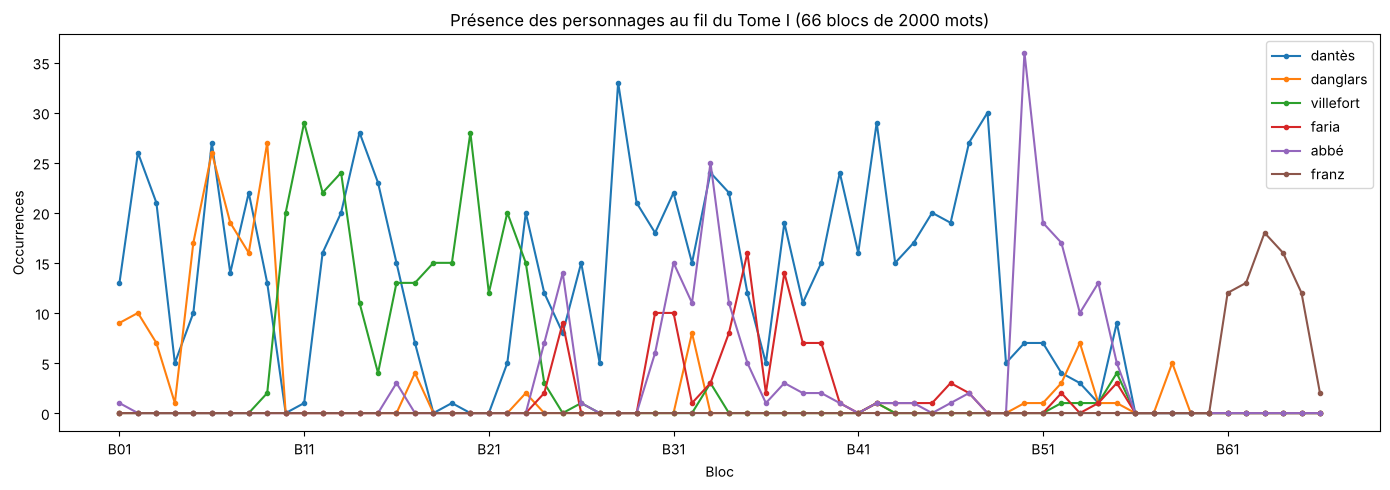

dantès     max dans B28 (33) — chapitre XV
danglars   max dans B09 (27) — chapitre V
villefort  max dans B11 (29) — chapitre VI
faria      max dans B35 (16) — chapitre XVIII
abbé       max dans B50 (36) — chapitre XXVI
franz      max dans B63 (18) — chapitre XXXI


In [43]:
# d) complément : roman ENTIER, pour voir Faria
blocs_all, _ = decouper_blocs(roman_clean, TAILLE)
dist = distribution_personnages(blocs_all, ['dantès', 'danglars', 'villefort', 'faria', 'abbé', 'franz'],
                                index=[f'B{i+1:02d}' for i in range(len(blocs_all))])
ax = dist.plot(figsize=(14, 5), marker='o', ms=3)
ax.set_title(f'Présence des personnages au fil du Tome I ({len(blocs_all)} blocs de 2000 mots)')
ax.set_xlabel('Bloc'); ax.set_ylabel('Occurrences')
plt.tight_layout(); save_fig('10_personnages_fil_du_roman')
for p in dist.columns:
    i = dist[p].idxmax()
    print(f'{p:<10} max dans {i} ({dist[p].max()}) — chapitre {chapitre_du_mot((int(i[1:])-1)*TAILLE, idx_chap)}')

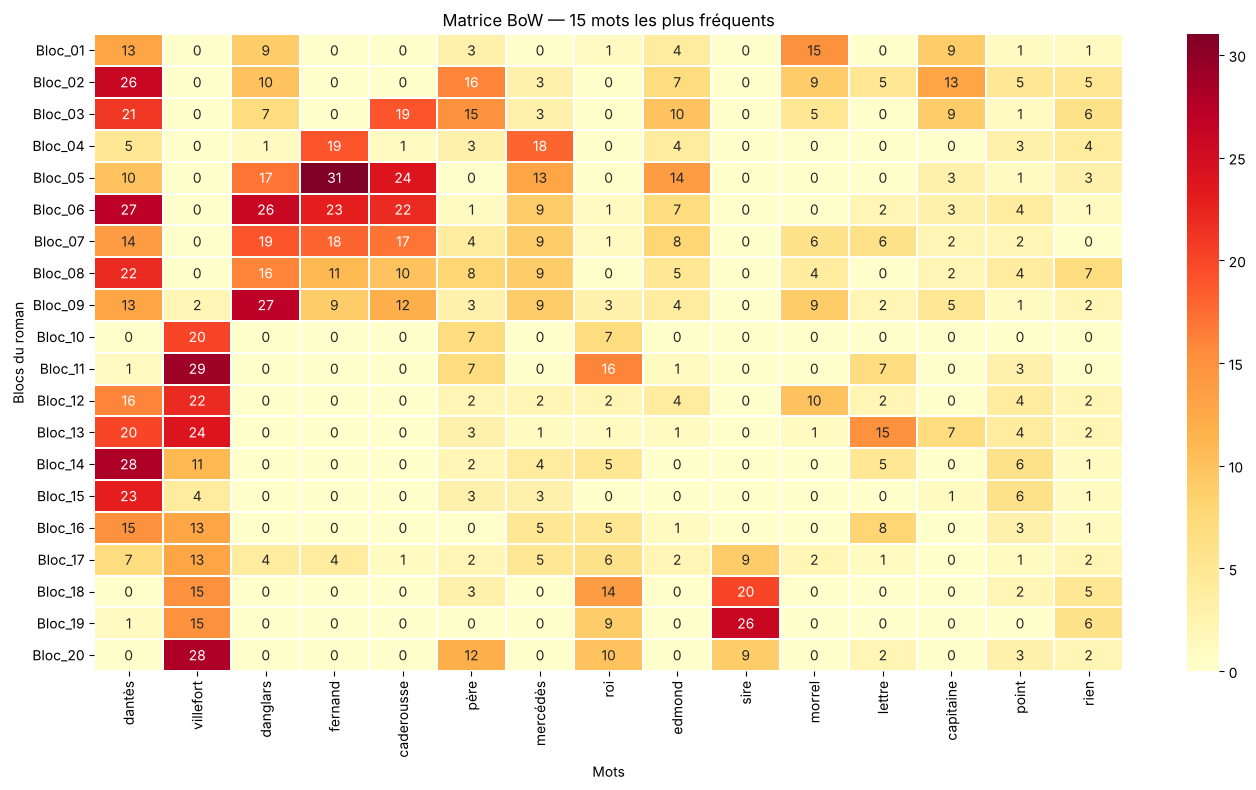

In [44]:
# e) Heatmap
top_mots = bow_df.sum().sort_values(ascending=False).head(15).index
plot_heatmap(bow_df[top_mots], 'Matrice BoW — 15 mots les plus fréquents', 'Mots', 'Blocs du roman',
             name='10_heatmap_bow', annot=True)

In [45]:
# f) Sparsité
dens = densite(X_bow)
print(f'f) Densité (300 mots, 20 blocs)  : {dens:.2f}%  -> {100-dens:.2f}% de zéros')
_, X_full, _ = build_bow(blocs_all, list(range(len(blocs_all))), stop_words=None, min_df=1, max_df=1.0,
                         max_features=None, token_pattern=r"(?u)\b[\w-]+\b")
dens_full = densite(X_full)
print(f'   Matrice SANS filtrage, roman entier : {X_full.shape[0]} × {X_full.shape[1]:,} '
      f'-> densité {dens_full:.2f}% / {100-dens_full:.2f}% de zéros')
print(f'   Mémoire dense : {X_full.shape[0]*X_full.shape[1]*8/1e6:.1f} Mo vs sparse CSR : '
      f'{(X_full.data.nbytes + X_full.indices.nbytes + X_full.indptr.nbytes)/1e6:.2f} Mo')

f) Densité (300 mots, 20 blocs)  : 45.07%  -> 54.93% de zéros
   Matrice SANS filtrage, roman entier : 66 × 11,142 -> densité 6.31% / 93.69% de zéros
   Mémoire dense : 5.9 Mo vs sparse CSR : 0.56 Mo


---
# Partie 11 — TF-IDF & Comparaison finale (`src/vectorization/tfidf_vectorizer.py`)

In [46]:
tfidf_vec, X_tfidf, tfidf_df = build_tfidf(blocs, noms_blocs, stop_words=sw_custom)
print(f'Matrice TF-IDF : {X_tfidf.shape}')
print(tfidf_df.iloc[:3, :6])
print('\na) Bloc_01 — 15 meilleurs scores TF-IDF :')
print(tfidf_df.loc['Bloc_01'].sort_values(ascending=False).head(15).to_string())

Matrice TF-IDF : (20, 300)
         affaire   agent  ailleurs    aime  air  allait
Bloc_01   0.0569  0.0569       0.0  0.0000  0.1     0.0
Bloc_02   0.0000  0.0000       0.0  0.0527  0.0     0.0
Bloc_03   0.0000  0.0000       0.0  0.1159  0.0     0.0

a) Bloc_01 — 15 meilleurs scores TF-IDF :
armateur     0.1982
navire       0.1941
bâtiment     0.1878
morrel       0.1869
leclère      0.1701
marin        0.1675
poste        0.1584
danglars     0.1523
capitaine    0.1523
île          0.1523
port         0.1484
château      0.1479
arrivé       0.1403
malheur      0.1395
empereur     0.1368


In [47]:
# b) Top 5 par bloc
top5_bloc = top_terms_per_doc(tfidf_df, 5)
top5_bloc.insert(0, 'chapitres', chap_blocs)
print(top5_bloc.to_string())
top5_bloc.to_csv(OUT_DIR / 'tfidf_top5_par_bloc.csv')

         chapitres           #1          #2          #3           #4           #5
Bloc_01        I–I     armateur      navire    bâtiment       morrel      leclère
Bloc_02       I–II     armateur     leclère   capitaine       morrel     danglars
Bloc_03      II–II       argent   vieillard  caderousse    capitaine          vin
Bloc_04     II–III      fernand        mère      larmes     attendez     mercédès
Bloc_05    III–III      fernand  caderousse     catalan     danglars      malheur
Bloc_06     III–IV      fernand        tuer  caderousse     danglars       papier
Bloc_07       IV–V      fernand  caderousse    danglars        repas        viens
Bloc_08        V–V  commissaire     fernand    danglars   caderousse        bruit
Bloc_09       V–VI     danglars  caderousse     fernand     armateur       morrel
Bloc_10      VI–VI     marquise    napoléon       comte    villefort  saint-méran
Bloc_11     VI–VII        renée    marquise        tuer    villefort      marquis
Bloc_12    VII–V

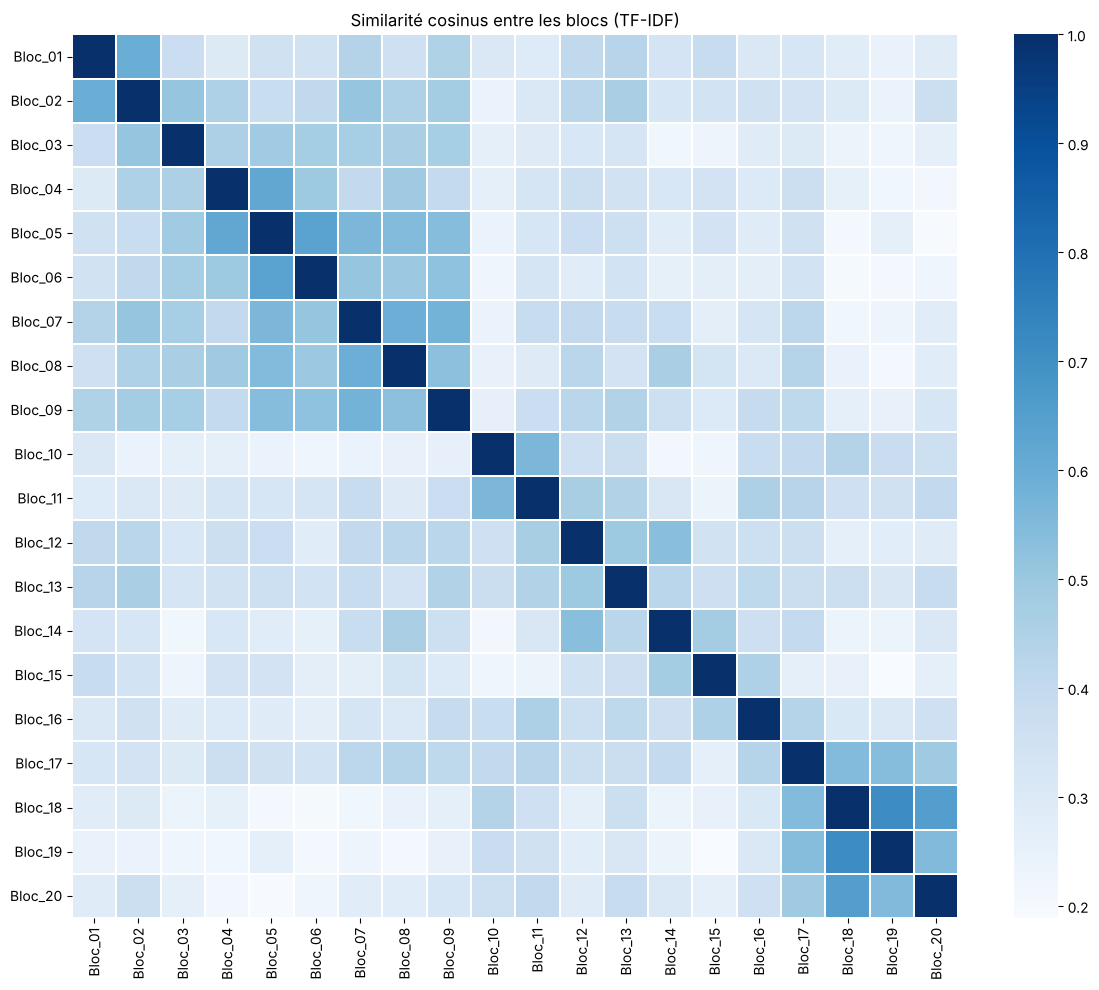

Blocs les plus similaires au Bloc_01 :
Bloc_02    0.596
Bloc_09    0.446
Bloc_07    0.437
Bloc_13    0.431
Bloc_12    0.407

c) Les 5 paires de blocs les plus proches :
Bloc_18  Bloc_19    0.709
         Bloc_20    0.653
Bloc_05  Bloc_06    0.637
Bloc_04  Bloc_05    0.618
Bloc_01  Bloc_02    0.596

   Les 3 paires les plus éloignées :
Bloc_06  Bloc_18    0.203
Bloc_05  Bloc_20    0.193
Bloc_15  Bloc_19    0.189


In [48]:
# c) Similarité cosinus
sim_df = similarity_matrix(X_tfidf, noms_blocs)
plot_heatmap(sim_df, 'Similarité cosinus entre les blocs (TF-IDF)', name='11_similarite_cosinus',
             cmap='Blues', figsize=(12, 10))
print('Blocs les plus similaires au Bloc_01 :')
print(sim_df['Bloc_01'].sort_values(ascending=False)[1:6].to_string())
paires = top_pairs(sim_df)
print('\nc) Les 5 paires de blocs les plus proches :'); print(paires.head(5).to_string())
print('\n   Les 3 paires les plus éloignées :'); print(paires.tail(3).to_string())

In [49]:
# d) Mini moteur de recherche
moteur = TfidfSearchEngine(tfidf_vec, X_tfidf, noms_blocs, preprocess=clean_text_v2)
for q in ['château if prison dantès', 'mariage fiançailles mercédès', 'complot lettre dénonciation',
          'navire capitaine mer']:
    print(f"Requête : '{q}'  (termes reconnus : {moteur.termes_reconnus(q)})")
    for b, sc in moteur.search(q):
        print(f'    {b} (ch. {chap_blocs[noms_blocs.index(b)]}) score = {sc}')

Requête : 'château if prison dantès'  (termes reconnus : ['château', 'prison', 'dantès'])
    Bloc_15 (ch. VIII–VIII) score = 0.2957
    Bloc_01 (ch. I–I) score = 0.1575
    Bloc_14 (ch. VII–VIII) score = 0.1553
Requête : 'mariage fiançailles mercédès'  (termes reconnus : ['fiançailles', 'mercédès'])
    Bloc_06 (ch. III–IV) score = 0.1416
    Bloc_08 (ch. V–V) score = 0.121
    Bloc_07 (ch. IV–V) score = 0.1203
Requête : 'complot lettre dénonciation'  (termes reconnus : ['lettre'])
    Bloc_13 (ch. VII–VII) score = 0.1847
    Bloc_11 (ch. VI–VII) score = 0.1363
    Bloc_16 (ch. VIII–IX) score = 0.1343
Requête : 'navire capitaine mer'  (termes reconnus : ['navire', 'capitaine', 'mer'])
    Bloc_01 (ch. I–I) score = 0.2533
    Bloc_13 (ch. VII–VII) score = 0.1243
    Bloc_02 (ch. I–II) score = 0.1206


In [50]:
# d) complément : même requête dans l'espace BoW
moteur_bow = TfidfSearchEngine(vectorizer, X_bow, noms_blocs, preprocess=clean_text_v2)
q = 'château if prison dantès'
for nom, m in [('BoW', moteur_bow), ('TF-IDF', moteur)]:
    sc = np.sort(m.scores(q))
    print(f'{nom:<7}: {[(b, float(s)) for b, s in m.search(q, 5)]}')
    print(f'{"":<7}  écart 1er / 2e = ×{sc[-1]/sc[-2]:.2f}')

BoW    : [('Bloc_15', 0.551), ('Bloc_14', 0.4263), ('Bloc_06', 0.3238), ('Bloc_02', 0.3147), ('Bloc_08', 0.3122)]
         écart 1er / 2e = ×1.29
TF-IDF : [('Bloc_15', 0.2957), ('Bloc_01', 0.1575), ('Bloc_14', 0.1553), ('Bloc_16', 0.1202), ('Bloc_06', 0.1199)]
         écart 1er / 2e = ×1.88


In [51]:
# e) BoW vs TF-IDF
for mot_test in ['dantès', 'armateur', 'leclère']:
    print(f"{mot_test:<9} Bloc_01 -> BoW = {bow_df.loc['Bloc_01', mot_test]:>3} | "
          f"TF-IDF = {tfidf_df.loc['Bloc_01', mot_test]:.4f} | rang BoW = "
          f"{list(bow_df.loc['Bloc_01'].sort_values(ascending=False).index).index(mot_test)+1} | rang TF-IDF = "
          f"{list(tfidf_df.loc['Bloc_01'].sort_values(ascending=False).index).index(mot_test)+1} | "
          f"IDF = {tfidf_vec.idf_[tfidf_vec.vocabulary_[mot_test]]:.3f}")
cmp = pd.DataFrame({'BoW Bloc_01': list(bow_df.loc['Bloc_01'].sort_values(ascending=False).head(10).index),
                    'TF-IDF Bloc_01': list(tfidf_df.loc['Bloc_01'].sort_values(ascending=False).head(10).index),
                    'BoW global': list(bow_df.sum().sort_values(ascending=False).head(10).index),
                    'TF-IDF global': list(tfidf_df.sum().sort_values(ascending=False).head(10).index)})
print(cmp.to_string())
print(f'\nChevauchement moyen des top-5 entre blocs : BoW = {chevauchement_top(bow_df):.2f} | '
      f'TF-IDF = {chevauchement_top(tfidf_df):.2f}  (plus bas = plus discriminant)')

dantès    Bloc_01 -> BoW =  13 | TF-IDF = 0.1190 | rang BoW = 3 | rang TF-IDF = 23 | IDF = 1.154
armateur  Bloc_01 -> BoW =  15 | TF-IDF = 0.1982 | rang BoW = 1 | rang TF-IDF = 1 | IDF = 1.847
leclère   Bloc_01 -> BoW =   5 | TF-IDF = 0.1701 | rang BoW = 13 | rang TF-IDF = 5 | IDF = 2.253
  BoW Bloc_01 TF-IDF Bloc_01  BoW global TF-IDF global
0    armateur       armateur      dantès        dantès
1      morrel         navire   villefort     villefort
2      dantès       bâtiment    danglars      danglars
3    bâtiment         morrel     fernand       fernand
4         île        leclère  caderousse      mercédès
5    danglars          marin        père          père
6      navire          poste    mercédès    caderousse
7   capitaine       danglars         roi        edmond
8       marin      capitaine      edmond           roi
9      arrivé            île        sire        morrel

Chevauchement moyen des top-5 entre blocs : BoW = 0.22 | TF-IDF = 0.09  (plus bas = plus discriminant)


---
# Récapitulatif des indicateurs clés

In [52]:
recap = pd.DataFrame([
    ('Caractères (roman extrait)', f'{len(roman):,}'),
    ('Mots (.split)', f'{nb_mots_split:,}'),
    ('Tokens NLTK (après nettoyage)', f'{len(tokens):,}'),
    ('Vocabulaire', f'{len(set(tokens)):,}'),
    ('Richesse lexicale (TTR)', f'{len(set(tokens))/len(tokens):.4f}'),
    ('Hapax', f'{len(hap):,} ({len(hap)/len(freq)*100:.1f}% du vocab.)'),
    ('Pente de Zipf', f"{fit['pente']:.2f}"),
    ('Tokens après stop words', f'{len(tokens_no_stop):,} (-{(1-len(tokens_no_stop)/len(tokens))*100:.1f}%)'),
    ('Réduction vocab. par stemming', f'{(1-v_ap/v_av)*100:.1f}%'),
    ('Matrice BoW / TF-IDF', f'{X_bow.shape[0]} × {X_bow.shape[1]}'),
    ('Densité BoW', f'{dens:.1f}%'),
], columns=['Indicateur', 'Valeur'])
print(recap.to_string(index=False))
recap.to_csv(OUT_DIR / 'recapitulatif.csv', index=False)

                   Indicateur                  Valeur
   Caractères (roman extrait)                 727,472
                Mots (.split)                 121,578
Tokens NLTK (après nettoyage)                 130,542
                  Vocabulaire                  11,142
      Richesse lexicale (TTR)                  0.0854
                        Hapax 5,434 (48.8% du vocab.)
                Pente de Zipf                   -1.15
      Tokens après stop words         50,389 (-61.4%)
Réduction vocab. par stemming                   47.7%
         Matrice BoW / TF-IDF                20 × 300
                  Densité BoW                   45.1%
